# Crop Yield Prediction Using Statistical Modeling and Machine Learning
**Course:** Statistical Modeling (24AM5PCSML) - AAT, B.M.S. College of Engineering, 2026-27

Integrated, reproducible pipeline covering Phase 1 (statistical modelling and validation)
and Phase 2 (feature selection, regularisation, machine-learning models, comparison).

Dataset: "Dataset for Crop Yield Prediction" (Laktionov, Semenov, Diachenko, 2026),
Zenodo record 18761663, CC-BY-4.0. https://zenodo.org/records/18761663
Yield and pesticide data originate from FAOSTAT; rainfall and temperature from the
Kaggle "Crop Yield Prediction Dataset" (patelris).

Run from the project root:  python src/crop_yield_pipeline.py

## 0. Setup

In [1]:
import json
import os
import time
import warnings
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.feature_selection import RFECV
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold, KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from statsmodels.stats.diagnostic import het_breuschpagan, linear_rainbow
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson, jarque_bera

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
np.random.seed(SEED)

ROOT = Path(__file__).resolve().parents[1] if "__file__" in globals() else Path.cwd()
DATA = ROOT / "data" / "raw" / "df_yield_merged.csv"
OUT = ROOT / "outputs"
FIG = OUT / "figures"
TAB = OUT / "tables"
for p in (FIG, TAB):
    p.mkdir(parents=True, exist_ok=True)

N_JOBS = int(os.environ.get("N_JOBS", "-1"))
RESULTS = {}  # every number used in the report is stored here

# Plot style (brand-neutral reference palette, light surface)
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, RED, GREY_MID = "#2a78d6", "#eb6834", "#e34948", "#f0efec"
DIVERGING = LinearSegmentedColormap.from_list("bluered", [BLUE, GREY_MID, RED])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10, "font.size": 10, "lines.linewidth": 2,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})


def savefig(name):
    plt.savefig(FIG / f"{name}.png")
    plt.close()
    print(f"  [figure saved] outputs/figures/{name}.png")
    if "__file__" not in globals():  # inside Jupyter: show the saved figure inline
        from IPython.display import Image, display
        display(Image(filename=str(FIG / f"{name}.png")))


def metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"R2": r2_score(y_true, y_pred), "MAE": mean_absolute_error(y_true, y_pred),
            "MSE": mse, "RMSE": float(np.sqrt(mse))}


def section(title):
    print("\n" + "=" * 78 + f"\n{title}\n" + "=" * 78)


pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## 1. Load data and audit quality

In [2]:
section("1. DATA LOADING AND QUALITY AUDIT")
raw = pd.read_csv(DATA)
print(f"Raw file: {DATA.name}  shape = {raw.shape}  (rows x columns)")
print("\nColumn data types:\n", raw.dtypes.astype(str).to_string())
print("\nFirst 5 rows:\n", raw.head().to_string())

missing = raw.isna().sum()
exact_dups = int(raw.duplicated().sum())
key = ["area", "year", "item"]
key_dups = int(raw.duplicated(key).sum())
varying = raw.groupby(key)[["value_hg_ha", "average_rain_fall_mm_per_year",
                            "pesticides_tonnes", "avg_temp"]].nunique().max()
print("\nMissing values per column:\n", missing.to_string())
print(f"\nExact duplicate rows: {exact_dups}")
print(f"Rows repeating an (area, year, item) key: {key_dups}")
print("Max distinct values within one key (shows which column causes the repeats):\n",
      varying.to_string())
rain_per_country = raw.groupby("area")["average_rain_fall_mm_per_year"].nunique().max()
print(f"Max distinct rainfall values per country across all years: {rain_per_country}")

RESULTS["raw"] = {"rows": int(raw.shape[0]), "cols": int(raw.shape[1]),
                  "missing_total": int(missing.sum()), "exact_duplicates": exact_dups,
                  "key_duplicates": key_dups,
                  "max_temp_values_per_key": int(varying["avg_temp"]),
                  "rain_values_per_country": int(rain_per_country)}


1. DATA LOADING AND QUALITY AUDIT
Raw file: df_yield_merged.csv  shape = (25932, 7)  (rows x columns)

Column data types:
 area                                 str
year                               int64
average_rain_fall_mm_per_year    float64
pesticides_tonnes                float64
avg_temp                         float64
item                                 str
value_hg_ha                        int64

First 5 rows:
       area  year  average_rain_fall_mm_per_year  pesticides_tonnes  avg_temp         item  value_hg_ha
0  Albania  1990                     1,485.0000           121.0000   16.3700        Maize        36613
1  Albania  1990                     1,485.0000           121.0000   16.3700     Potatoes        66667
2  Albania  1990                     1,485.0000           121.0000   16.3700  Rice, paddy        23333
3  Albania  1990                     1,485.0000           121.0000   16.3700      Sorghum        12500
4  Albania  1990                     1,485.0000           

## 2. Cleaning and feature engineering

In [3]:
section("2. CLEANING AND FEATURE ENGINEERING")
# The repeats come from several temperature stations per country being merged in:
# yield, rainfall and pesticides are identical inside a key, only avg_temp varies.
# Keeping them would weight some countries (e.g. India) up to 19x and would put the
# same yield value in both train and test (leakage). We average temperature per key.
df = (raw.groupby(key, as_index=False)
         .agg(average_rain_fall_mm_per_year=("average_rain_fall_mm_per_year", "first"),
              pesticides_tonnes=("pesticides_tonnes", "first"),
              avg_temp=("avg_temp", "mean"),
              value_hg_ha=("value_hg_ha", "first")))
df = df.rename(columns={"area": "country", "item": "crop",
                        "average_rain_fall_mm_per_year": "avg_rainfall_mm",
                        "avg_temp": "avg_temp_c"})
# Target: 1 hectogram = 0.1 kg, 1 tonne = 10,000 hg  ->  t/ha = hg/ha / 10,000
df["yield_t_ha"] = df["value_hg_ha"] / 10_000
# Pesticide use is extremely right-skewed (national totals) -> log(1+x)
df["log_pesticides"] = np.log1p(df["pesticides_tonnes"])
df = df.sort_values(["country", "crop", "year"]).reset_index(drop=True)

NUM = ["avg_rainfall_mm", "log_pesticides", "avg_temp_c", "year"]
CAT = ["crop", "country"]
TARGET = "yield_t_ha"
ALL_FEATURES = NUM + CAT

print(f"Clean analytical dataset shape: {df.shape}")
print(f"Countries: {df.country.nunique()}, crops: {df.crop.nunique()}, "
      f"years: {df.year.min()}-{df.year.max()}")
print("\nRows per crop:\n", df.crop.value_counts().to_string())

# Outlier screening (IQR rule) - reported, not removed: extreme yields are real
# (e.g. potatoes/cassava are bulky tuber crops with naturally high t/ha).
out_rows = []
for c in ["avg_rainfall_mm", "pesticides_tonnes", "log_pesticides", "avg_temp_c", TARGET]:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = int(((df[c] < lo) | (df[c] > hi)).sum())
    out_rows.append({"feature": c, "Q1": q1, "Q3": q3, "lower_fence": lo,
                     "upper_fence": hi, "n_outliers": n, "pct_outliers": 100 * n / len(df)})
outliers = pd.DataFrame(out_rows)
print("\nIQR outlier screening:\n", outliers.to_string(index=False))
outliers.to_csv(TAB / "outlier_screening.csv", index=False)
# Within-crop outliers for the target (a fairer check since crops differ in scale)
wc = df.groupby("crop")[TARGET].transform
q1c, q3c = wc(lambda s: s.quantile(0.25)), wc(lambda s: s.quantile(0.75))
within_crop_out = int(((df[TARGET] < q1c - 1.5 * (q3c - q1c)) |
                       (df[TARGET] > q3c + 1.5 * (q3c - q1c))).sum())
print(f"Target outliers when the IQR rule is applied within each crop: {within_crop_out}")

RESULTS["clean"] = {"rows": int(len(df)), "countries": int(df.country.nunique()),
                    "crops": int(df.crop.nunique()), "year_min": int(df.year.min()),
                    "year_max": int(df.year.max()),
                    "crop_counts": df.crop.value_counts().to_dict(),
                    "outliers": outliers.set_index("feature")["n_outliers"].to_dict(),
                    "target_outliers_within_crop": within_crop_out,
                    "min_yield": float(df[TARGET].min()), "max_yield": float(df[TARGET].max())}
df.to_csv(ROOT / "data" / "crop_yield_clean.csv", index=False)


2. CLEANING AND FEATURE ENGINEERING
Clean analytical dataset shape: (13130, 9)
Countries: 101, crops: 10, years: 1990-2013

Rows per crop:
 crop
Potatoes                2091
Maize                   2028
Wheat                   1810
Rice, paddy             1502
Sorghum                 1435
Soybeans                1242
Sweet potatoes          1163
Cassava                  941
Plantains and others     464
Yams                     454

IQR outlier screening:
           feature       Q1          Q3  lower_fence  upper_fence  n_outliers  pct_outliers
  avg_rainfall_mm 608.0000  1,651.0000    -956.5000   3,215.5000         207        1.5765
pesticides_tonnes 264.5300 13,335.2200 -19,341.5050  32,941.2550        1936       14.7449
   log_pesticides   5.5817      9.4982      -0.2930      15.3730           0        0.0000
       avg_temp_c  15.7540     25.7937       0.6945      40.8532           0        0.0000
       yield_t_ha   1.8000      9.7152     -10.0728      21.5881         814        

## 3. Train/test split (done BEFORE any model fitting)

In [4]:
section("3. TRAIN / TEST SPLIT")
train_df, test_df = train_test_split(df, test_size=0.20, random_state=SEED)
train_df, test_df = train_df.copy(), test_df.copy()
X_train, y_train = train_df[ALL_FEATURES], train_df[TARGET]
X_test, y_test = test_df[ALL_FEATURES], test_df[TARGET]
CV = KFold(n_splits=5, shuffle=True, random_state=SEED)  # same folds for every model
print(f"Train: {len(train_df)} rows, Test: {len(test_df)} rows (80/20, seed={SEED})")
RESULTS["split"] = {"train": int(len(train_df)), "test": int(len(test_df))}


3. TRAIN / TEST SPLIT


Train: 10504 rows, Test: 2626 rows (80/20, seed=42)


## 4. Exploratory Data Analysis


4. EXPLORATORY DATA ANALYSIS (descriptive, full clean dataset)
                   count        mean     median       mode           variance         std        min          max  skewness  kurtosis
avg_rainfall_mm    13130  1,157.2388 1,083.0000   630.0000       552,974.4046    743.6225    51.0000   3,240.0000    0.7461    0.1038
pesticides_tonnes  13130 14,838.6979 2,172.2000    88.0000 1,132,487,705.3269 33,652.4547     0.0400 367,778.0000    5.5340   43.4866
log_pesticides     13130      7.4743     7.6840     4.4886             6.6440      2.5776     0.0392      12.8152   -0.3879   -0.5195
avg_temp_c         13130     19.8627    20.6200    27.2000            44.3820      6.6620     1.3000      30.4200   -0.5446   -0.8164
year               13130  2,001.6228 2,001.0000 2,012.0000            49.4650      7.0331 1,990.0000   2,013.0000    0.0023   -1.2699
yield_t_ha         13130      7.0969     3.9543     2.0000            62.6065      7.9124     0.0050      50.1412    2.0768    4.987

  [figure saved] outputs/figures/01_histograms.png


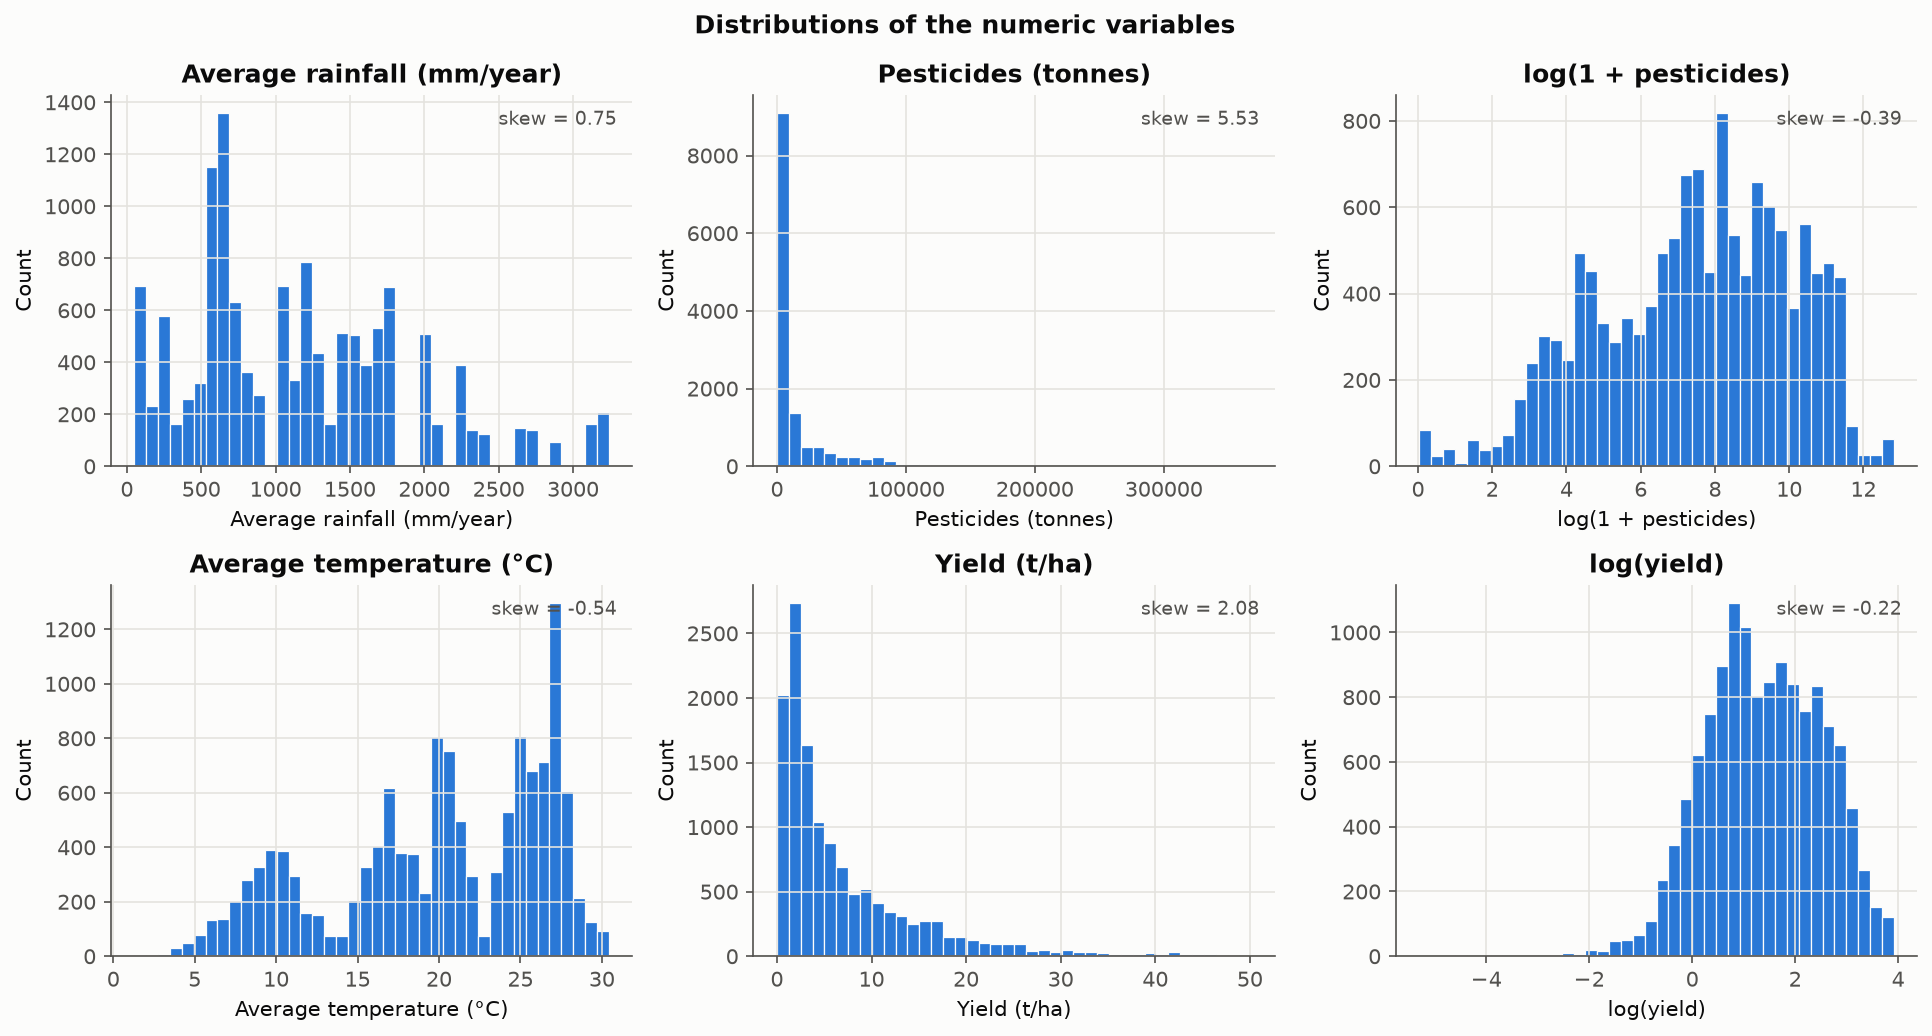

  [figure saved] outputs/figures/02_boxplot_yield_by_crop.png


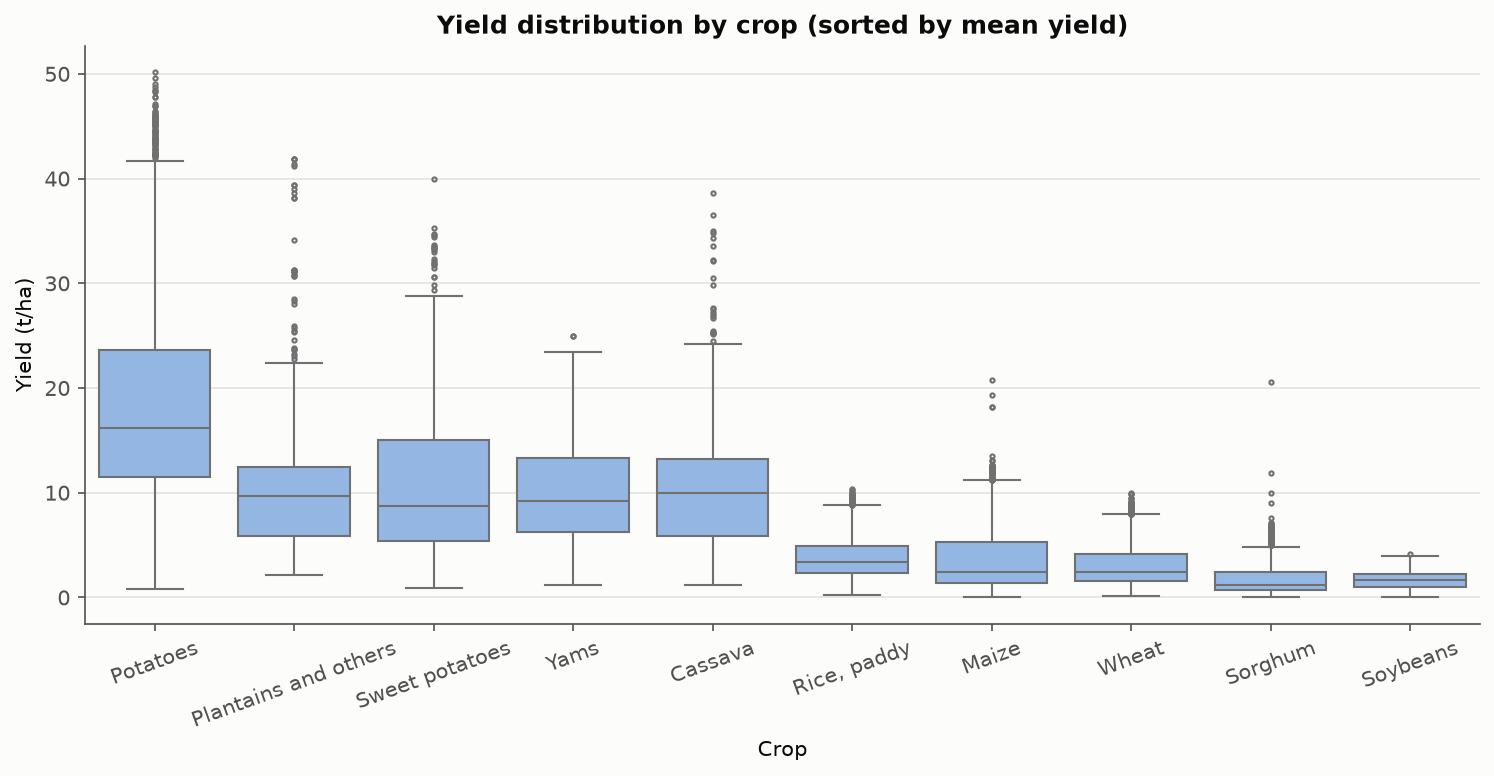

  [figure saved] outputs/figures/03_boxplots_numeric.png


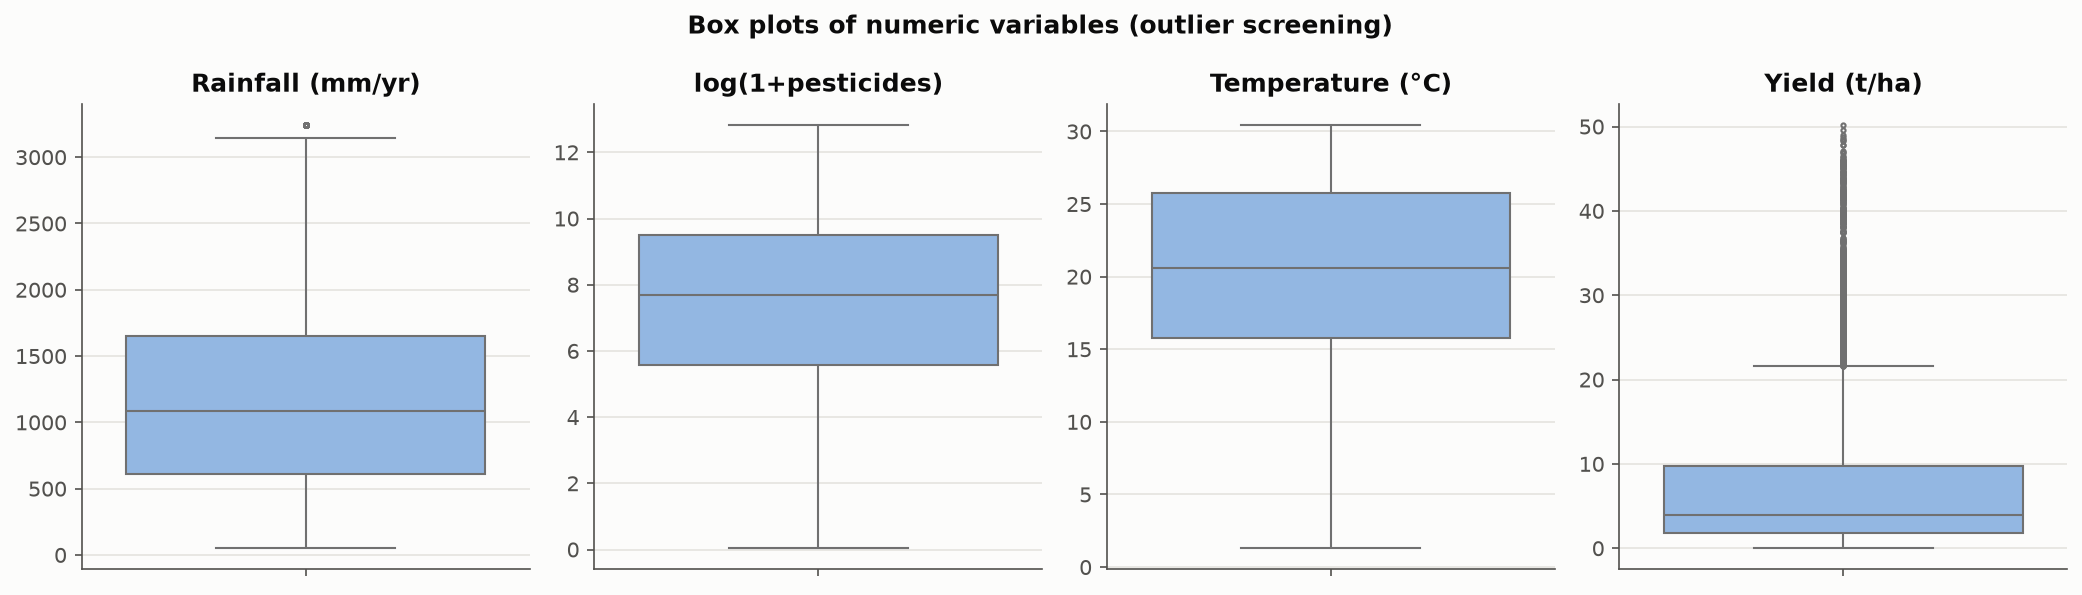

  [figure saved] outputs/figures/04_scatter_features_vs_yield.png


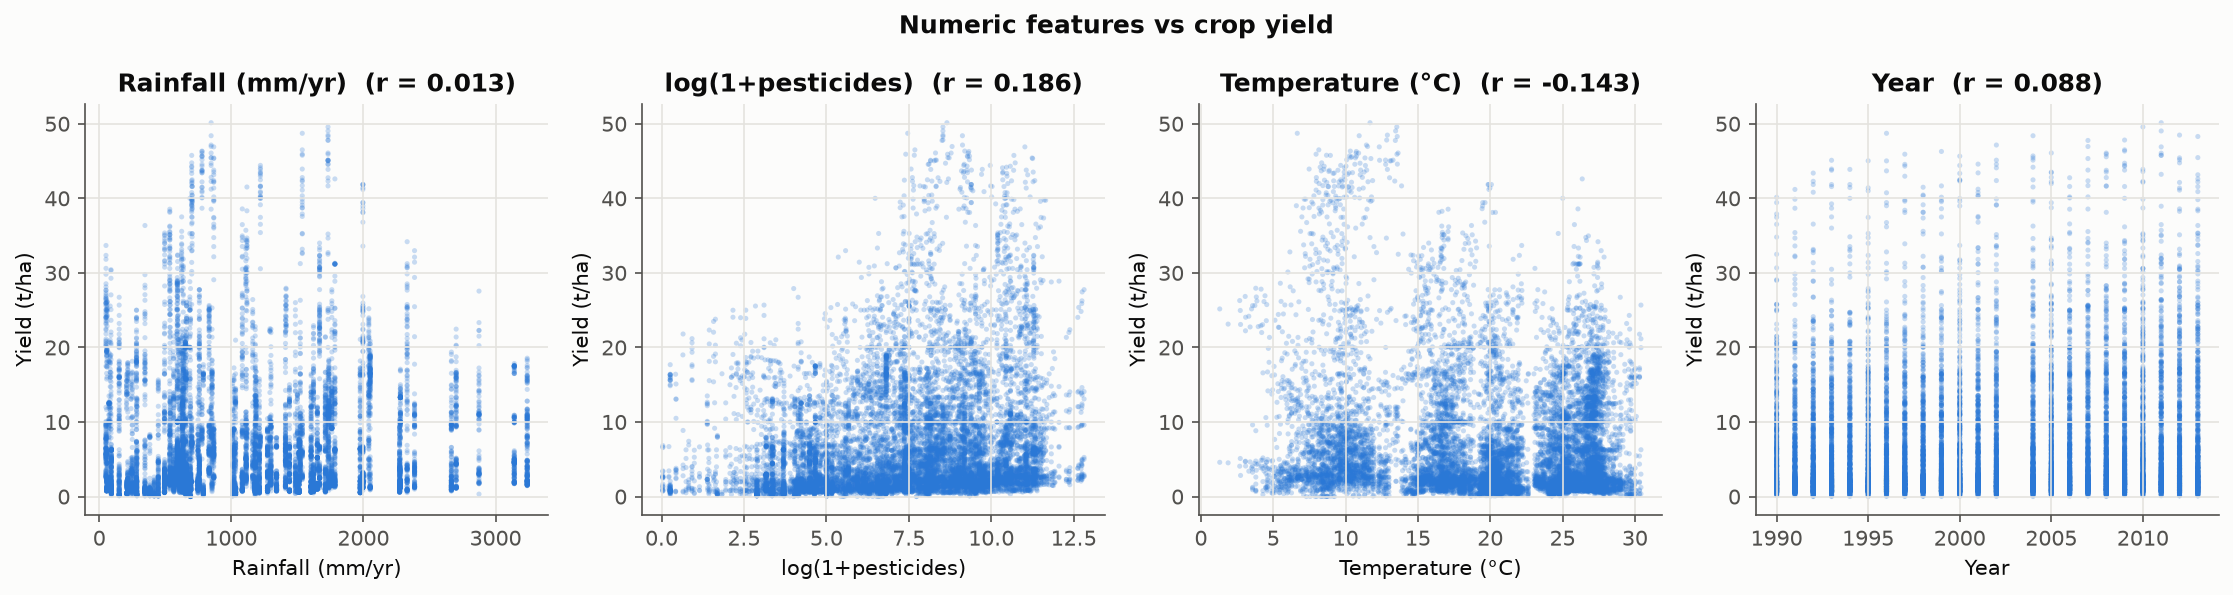


Pearson correlation matrix:
                    avg_rainfall_mm  pesticides_tonnes  log_pesticides  avg_temp_c    year  yield_t_ha
avg_rainfall_mm             1.0000             0.0770          0.1030      0.3440 -0.0070      0.0130
pesticides_tonnes           0.0770             1.0000          0.5780     -0.0950  0.0840      0.0920
log_pesticides              0.1030             0.5780          1.0000     -0.3400  0.0740      0.1860
avg_temp_c                  0.3440            -0.0950         -0.3400      1.0000  0.0050     -0.1430
year                       -0.0070             0.0840          0.0740      0.0050  1.0000      0.0880
yield_t_ha                  0.0130             0.0920          0.1860     -0.1430  0.0880      1.0000

Spearman correlation matrix:
                    avg_rainfall_mm  pesticides_tonnes  log_pesticides  avg_temp_c    year  yield_t_ha
avg_rainfall_mm             1.0000             0.0560          0.0560      0.3080 -0.0070      0.0750
pesticides_tonnes    

  [figure saved] outputs/figures/05_correlation_heatmap.png


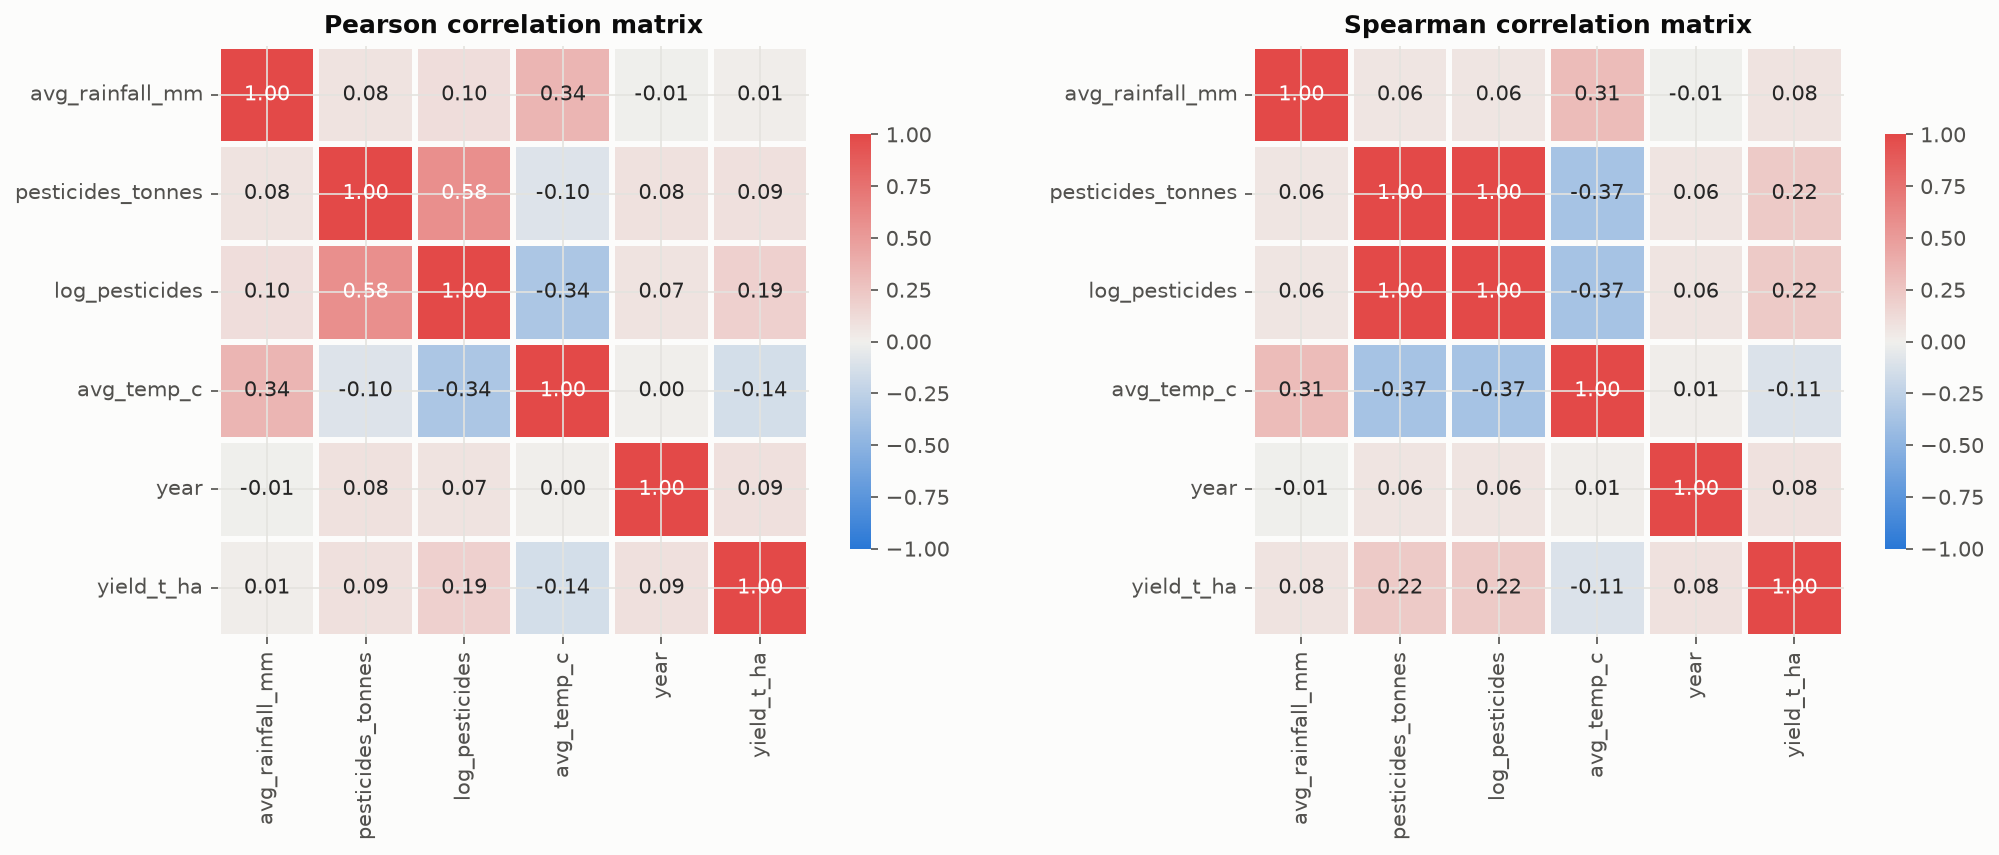

  [figure saved] outputs/figures/06_yield_trend_by_crop.png


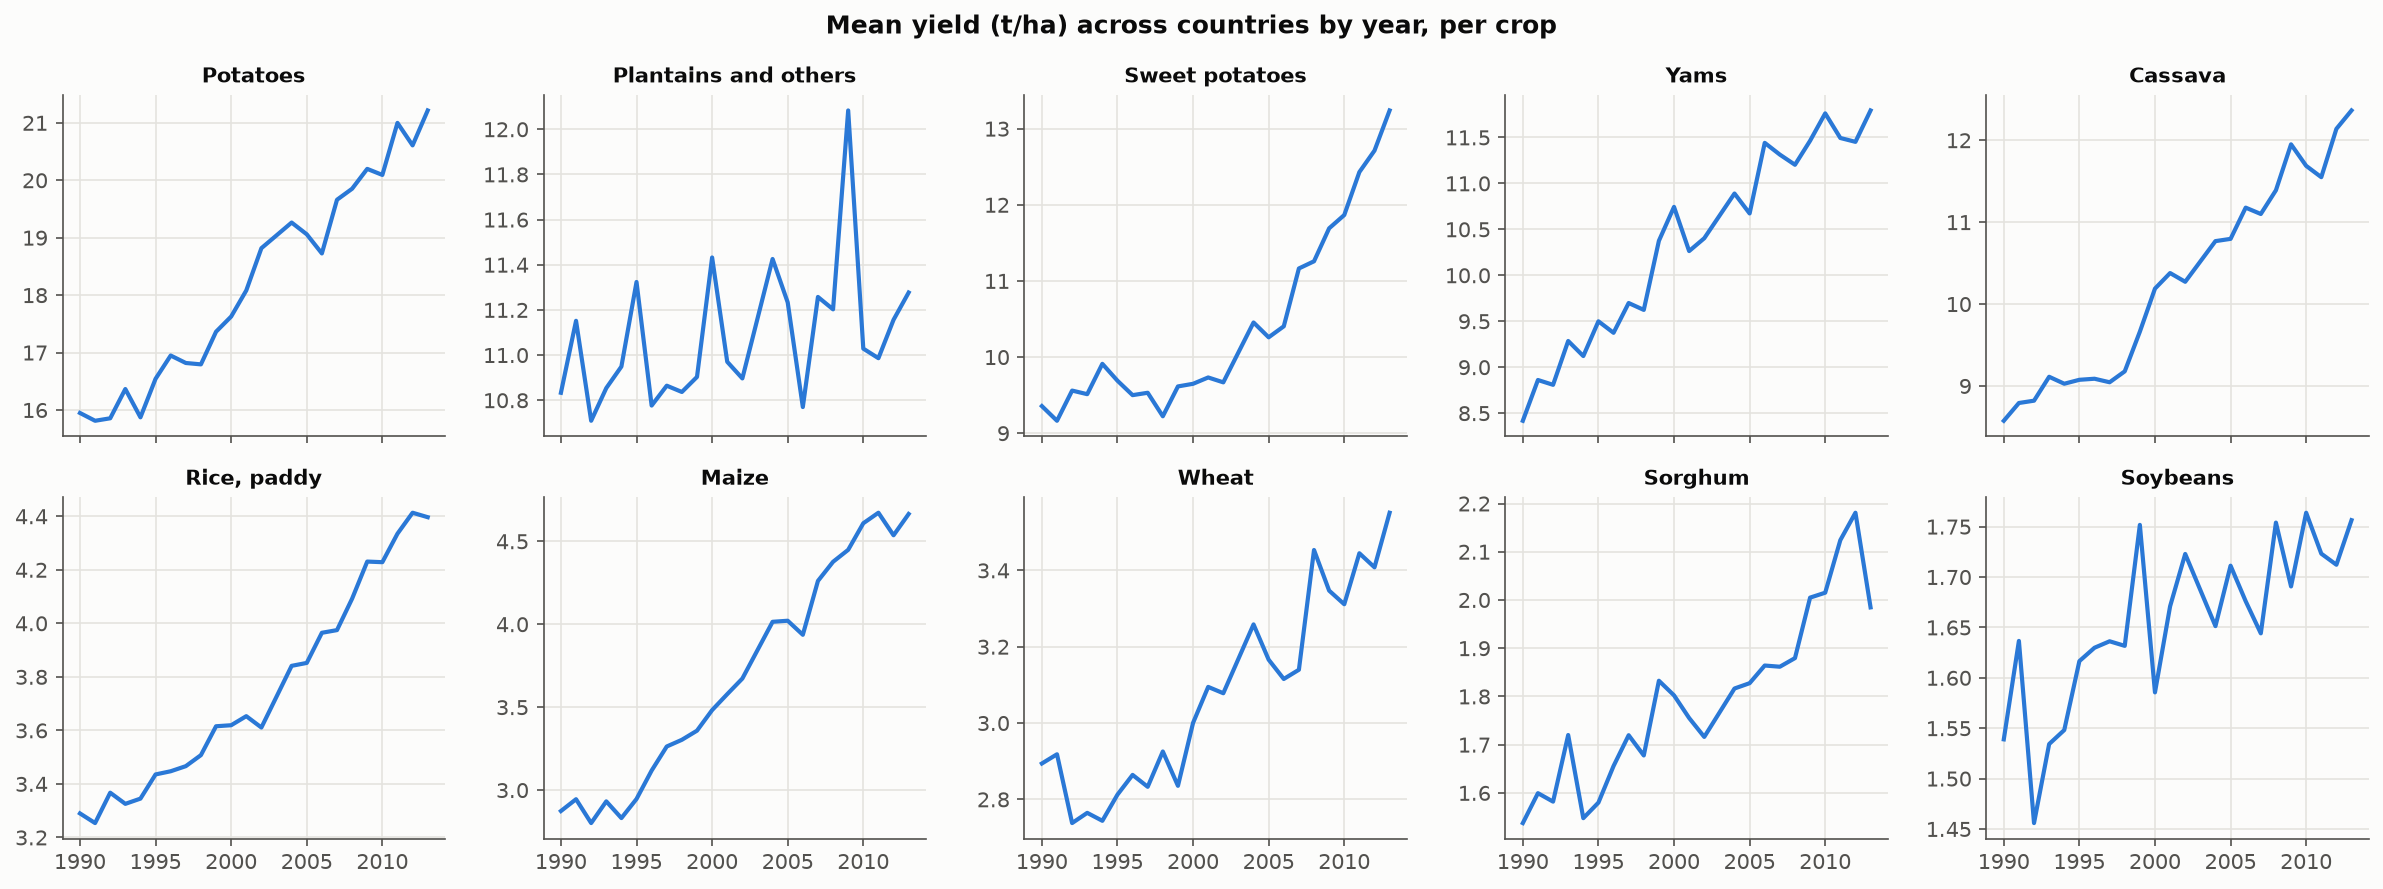


Eta squared (share of yield variance explained by group): {'crop': np.float64(0.5373956705070175), 'country': np.float64(0.20881462264511064)}
One-way ANOVA yield ~ crop: F = 1693.46, p = 0.000e+00


In [5]:
section("4. EXPLORATORY DATA ANALYSIS (descriptive, full clean dataset)")
desc_cols = ["avg_rainfall_mm", "pesticides_tonnes", "log_pesticides", "avg_temp_c", "year", TARGET]
desc = pd.DataFrame({
    "count": df[desc_cols].count(), "mean": df[desc_cols].mean(),
    "median": df[desc_cols].median(), "mode": df[desc_cols].mode().iloc[0],
    "variance": df[desc_cols].var(), "std": df[desc_cols].std(),
    "min": df[desc_cols].min(), "max": df[desc_cols].max(),
    "skewness": df[desc_cols].skew(), "kurtosis": df[desc_cols].kurt()})
print(desc.to_string())
desc.to_csv(TAB / "descriptive_statistics.csv")
RESULTS["descriptive"] = desc.round(4).to_dict(orient="index")

crop_stats = df.groupby("crop")[TARGET].agg(["count", "mean", "median", "std", "min", "max"]) \
               .sort_values("mean", ascending=False)
print("\nYield (t/ha) by crop:\n", crop_stats.to_string())
crop_stats.to_csv(TAB / "yield_by_crop.csv")
RESULTS["yield_by_crop"] = crop_stats.round(3).to_dict(orient="index")

# Histograms
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
hist_spec = [("avg_rainfall_mm", "Average rainfall (mm/year)"),
             ("pesticides_tonnes", "Pesticides (tonnes)"),
             ("log_pesticides", "log(1 + pesticides)"),
             ("avg_temp_c", "Average temperature (°C)"),
             (TARGET, "Yield (t/ha)"), ("log_yield", "log(yield)")]
df["log_yield"] = np.log(df[TARGET])
for ax, (c, lab) in zip(axes.ravel(), hist_spec):
    ax.hist(df[c], bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
    ax.set_title(lab)
    ax.set_xlabel(lab)
    ax.set_ylabel("Count")
    ax.text(0.97, 0.92, f"skew = {df[c].skew():.2f}", transform=ax.transAxes,
            ha="right", color=INK2, fontsize=9)
fig.suptitle("Distributions of the numeric variables", fontweight="bold")
plt.tight_layout()
savefig("01_histograms")
df = df.drop(columns="log_yield")

# Box plots: yield by crop + numeric features
order = crop_stats.index.tolist()
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=df, x="crop", y=TARGET, order=order, color="#86b6ef",
            fliersize=2, linewidth=1, ax=ax)
ax.set_title("Yield distribution by crop (sorted by mean yield)")
ax.set_xlabel("Crop")
ax.set_ylabel("Yield (t/ha)")
plt.xticks(rotation=20)
savefig("02_boxplot_yield_by_crop")

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, (c, lab) in zip(axes, [("avg_rainfall_mm", "Rainfall (mm/yr)"),
                               ("log_pesticides", "log(1+pesticides)"),
                               ("avg_temp_c", "Temperature (°C)"), (TARGET, "Yield (t/ha)")]):
    sns.boxplot(y=df[c], color="#86b6ef", fliersize=2, linewidth=1, ax=ax)
    ax.set_title(lab)
    ax.set_ylabel("")
fig.suptitle("Box plots of numeric variables (outlier screening)", fontweight="bold")
plt.tight_layout()
savefig("03_boxplots_numeric")

# Scatter plots vs yield
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, (c, lab) in zip(axes, [("avg_rainfall_mm", "Rainfall (mm/yr)"),
                               ("log_pesticides", "log(1+pesticides)"),
                               ("avg_temp_c", "Temperature (°C)"), ("year", "Year")]):
    ax.scatter(df[c], df[TARGET], s=6, alpha=0.25, color=BLUE, edgecolors="none")
    r = df[[c, TARGET]].corr().iloc[0, 1]
    ax.set_title(f"{lab}  (r = {r:.3f})")
    ax.set_xlabel(lab)
    ax.set_ylabel("Yield (t/ha)")
fig.suptitle("Numeric features vs crop yield", fontweight="bold")
plt.tight_layout()
savefig("04_scatter_features_vs_yield")

# Correlation matrices + heatmap
corr_cols = ["avg_rainfall_mm", "pesticides_tonnes", "log_pesticides", "avg_temp_c", "year", TARGET]
pearson = df[corr_cols].corr(method="pearson")
spearman = df[corr_cols].corr(method="spearman")
print("\nPearson correlation matrix:\n", pearson.round(3).to_string())
print("\nSpearman correlation matrix:\n", spearman.round(3).to_string())
pearson.to_csv(TAB / "correlation_pearson.csv")
spearman.to_csv(TAB / "correlation_spearman.csv")
RESULTS["corr_with_yield"] = {"pearson": pearson[TARGET].round(4).to_dict(),
                              "spearman": spearman[TARGET].round(4).to_dict()}
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (m, name) in zip(axes, [(pearson, "Pearson"), (spearman, "Spearman")]):
    sns.heatmap(m, annot=True, fmt=".2f", cmap=DIVERGING, vmin=-1, vmax=1, center=0,
                square=True, linewidths=2, linecolor=SURFACE, cbar_kws={"shrink": 0.7}, ax=ax)
    ax.set_title(f"{name} correlation matrix")
plt.tight_layout()
savefig("05_correlation_heatmap")

# Yield trend over time per crop (small multiples, one colour)
fig, axes = plt.subplots(2, 5, figsize=(16, 6), sharex=True)
for ax, crop in zip(axes.ravel(), order):
    s = df[df.crop == crop].groupby("year")[TARGET].mean()
    ax.plot(s.index, s.values, color=BLUE)
    ax.set_title(crop, fontsize=10)
fig.suptitle("Mean yield (t/ha) across countries by year, per crop", fontweight="bold")
plt.tight_layout()
savefig("06_yield_trend_by_crop")

# Association of categorical variables with yield: eta squared (one-way ANOVA)
def eta_squared(cat, y):
    grand = y.mean()
    ss_between = sum(len(g) * (g.mean() - grand) ** 2 for _, g in y.groupby(cat))
    return ss_between / ((y - grand) ** 2).sum()

eta = {c: eta_squared(df[c], df[TARGET]) for c in CAT}
anova_crop = stats.f_oneway(*[g.values for _, g in df.groupby("crop")[TARGET]])
print(f"\nEta squared (share of yield variance explained by group): {eta}")
print(f"One-way ANOVA yield ~ crop: F = {anova_crop.statistic:.2f}, p = {anova_crop.pvalue:.3e}")
RESULTS["eta_squared"] = eta
RESULTS["anova_crop"] = {"F": float(anova_crop.statistic), "p": float(anova_crop.pvalue)}

## 5. Simple Linear Regression


5. SIMPLE LINEAR REGRESSION
Training-set correlations with yield:
 avg_rainfall_mm    0.0168
log_pesticides     0.1832
avg_temp_c        -0.1401
year               0.0879
Selected predictor for SLR: log_pesticides
                            OLS Regression Results                            
Dep. Variable:             yield_t_ha   R-squared:                       0.034
Model:                            OLS   Adj. R-squared:                  0.033
Method:                 Least Squares   F-statistic:                     364.6
Date:                Wed, 25 Nov 2026   Prob (F-statistic):           6.44e-80
Time:                        19:04:39   Log-Likelihood:                -36415.
No. Observations:               10504   AIC:                         7.283e+04
Df Residuals:                   10502   BIC:                         7.285e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                     

  [figure saved] outputs/figures/07_slr_regression_line.png


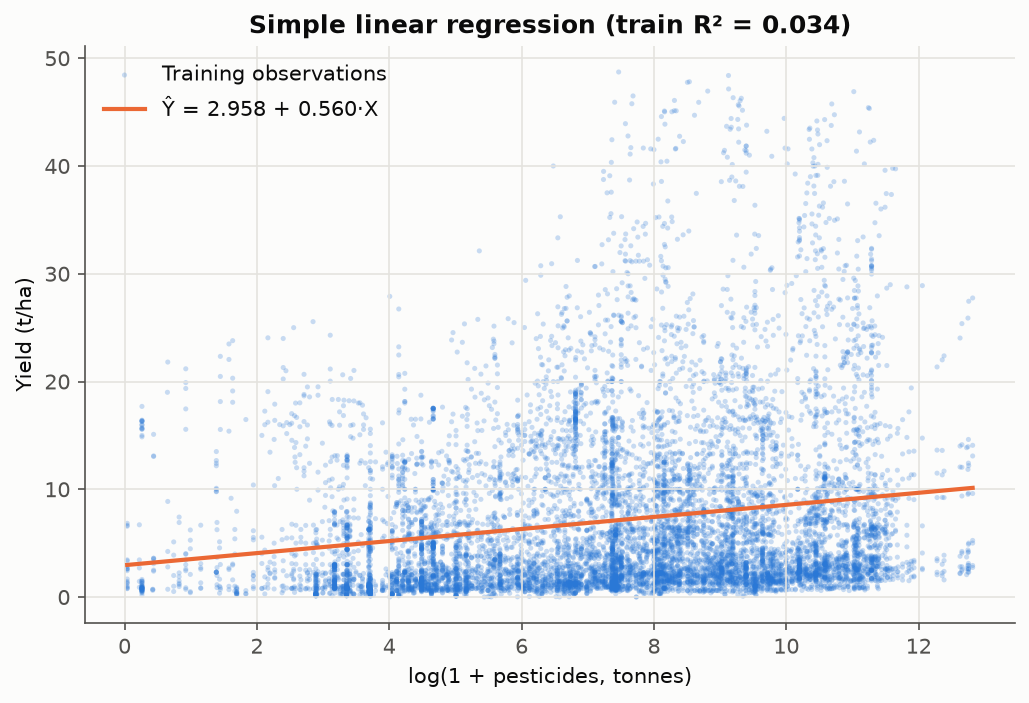

In [6]:
section("5. SIMPLE LINEAR REGRESSION")
# Choose X = numeric feature with the strongest |Pearson r| with yield in TRAINING data only
train_corr = train_df[NUM + [TARGET]].corr()[TARGET].drop(TARGET)
slr_x = train_corr.abs().idxmax()
print("Training-set correlations with yield:\n", train_corr.round(4).to_string())
print(f"Selected predictor for SLR: {slr_x}")

slr = smf.ols(f"{TARGET} ~ {slr_x}", data=train_df).fit()
print(slr.summary())
slr_pred = slr.predict(test_df)
slr_test = metrics(y_test, slr_pred)
slr_train = metrics(y_train, slr.fittedvalues)
print("Test metrics:", {k: round(v, 4) for k, v in slr_test.items()})
RESULTS["slr"] = {"x": slr_x, "b0": slr.params["Intercept"], "b1": slr.params[slr_x],
                  "b1_se": slr.bse[slr_x], "b1_p": slr.pvalues[slr_x],
                  "b1_ci": slr.conf_int().loc[slr_x].tolist(), "r2_train": slr.rsquared,
                  "F": slr.fvalue, "F_p": slr.f_pvalue, "test": slr_test, "train": slr_train,
                  "train_corr": train_corr.to_dict()}

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(train_df[slr_x], y_train, s=6, alpha=0.25, color=BLUE, edgecolors="none",
           label="Training observations")
xs = np.linspace(train_df[slr_x].min(), train_df[slr_x].max(), 100)
ax.plot(xs, slr.params["Intercept"] + slr.params[slr_x] * xs, color=ORANGE,
        label=f"Ŷ = {slr.params['Intercept']:.3f} + {slr.params[slr_x]:.3f}·X")
ax.set_xlabel("log(1 + pesticides, tonnes)" if slr_x == "log_pesticides" else slr_x)
ax.set_ylabel("Yield (t/ha)")
ax.set_title(f"Simple linear regression (train R² = {slr.rsquared:.3f})")
ax.legend(frameon=False)
savefig("07_slr_regression_line")

## 6. Multiple Linear Regression

In [7]:
section("6. MULTIPLE LINEAR REGRESSION (numeric features + crop dummies)")
# Crop enters as dummy variables (reference category = Cassava, alphabetically first).
# Country is NOT included here: rainfall is constant within each country, so rainfall
# and country dummies would be perfectly collinear. Country is introduced in Phase 2.
MLR_FORMULA = f"{TARGET} ~ avg_rainfall_mm + log_pesticides + avg_temp_c + year + C(crop)"
mlr = smf.ols(MLR_FORMULA, data=train_df).fit()
print(mlr.summary())
mlr_pred = mlr.predict(test_df)
mlr_test = metrics(y_test, mlr_pred)
print("Test metrics:", {k: round(v, 4) for k, v in mlr_test.items()})
coef_tab = pd.DataFrame({"coef": mlr.params, "std_err": mlr.bse, "t": mlr.tvalues,
                         "p_value": mlr.pvalues, "ci_low": mlr.conf_int()[0],
                         "ci_high": mlr.conf_int()[1]})
coef_tab.to_csv(TAB / "mlr_coefficients.csv")

# Standardised coefficients of the numeric predictors (per 1 SD change in X)
sd = train_df[NUM].std()
std_effect = (mlr.params[NUM] * sd).rename("effect_of_1SD_increase_t_ha")
print("\nEffect of a one-standard-deviation increase in each numeric feature (t/ha):\n",
      std_effect.round(4).to_string())
RESULTS["mlr"] = {"formula": MLR_FORMULA, "coef": coef_tab.round(6).to_dict(orient="index"),
                  "r2_train": mlr.rsquared, "adj_r2_train": mlr.rsquared_adj, "F": mlr.fvalue,
                  "F_p": mlr.f_pvalue, "aic": mlr.aic, "bic": mlr.bic, "test": mlr_test,
                  "train": metrics(y_train, mlr.fittedvalues), "n_params": int(len(mlr.params)),
                  "std_effect": std_effect.to_dict(), "sd": sd.to_dict()}


6. MULTIPLE LINEAR REGRESSION (numeric features + crop dummies)
                            OLS Regression Results                            
Dep. Variable:             yield_t_ha   R-squared:                       0.607
Model:                            OLS   Adj. R-squared:                  0.606
Method:                 Least Squares   F-statistic:                     1244.
Date:                Wed, 25 Nov 2026   Prob (F-statistic):               0.00
Time:                        19:04:41   Log-Likelihood:                -31694.
No. Observations:               10504   AIC:                         6.342e+04
Df Residuals:                   10490   BIC:                         6.352e+04
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------


Effect of a one-standard-deviation increase in each numeric feature (t/ha):
 avg_rainfall_mm   -0.1474
log_pesticides     1.4792
avg_temp_c        -1.0265
year               0.5927


## 7. Regression assumption testing


7. REGRESSION ASSUMPTION TESTING (MLR, training data)

--- MLR on raw yield (t/ha) ---
           rainbow_F: 1.02249
           rainbow_p: 0.210363
           shapiro_W: 0.882061
           shapiro_p: 5.00442e-52
                  jb: 21062.3
                jb_p: 0
          resid_skew: 1.51311
      resid_kurtosis: 9.24229
               bp_LM: 1797.24
                bp_p: 0
                bp_F: 166.564
              bp_F_p: 0
     dw_random_order: 2.00899
      dw_panel_order: 0.195345



Variance Inflation Factors:
                         feature    VIF
               C(crop)[T.Maize] 2.7410
C(crop)[T.Plantains and others] 1.4430
            C(crop)[T.Potatoes] 2.8840
         C(crop)[T.Rice, paddy] 2.3330
             C(crop)[T.Sorghum] 2.2840
            C(crop)[T.Soybeans] 2.1730
      C(crop)[T.Sweet potatoes] 2.0360
               C(crop)[T.Wheat] 2.7290
                C(crop)[T.Yams] 1.4310
                avg_rainfall_mm 1.2590
                 log_pesticides 1.2270
                     avg_temp_c 1.4720
                           year 1.0090


  [figure saved] outputs/figures/08_mlr_diagnostics_raw.png


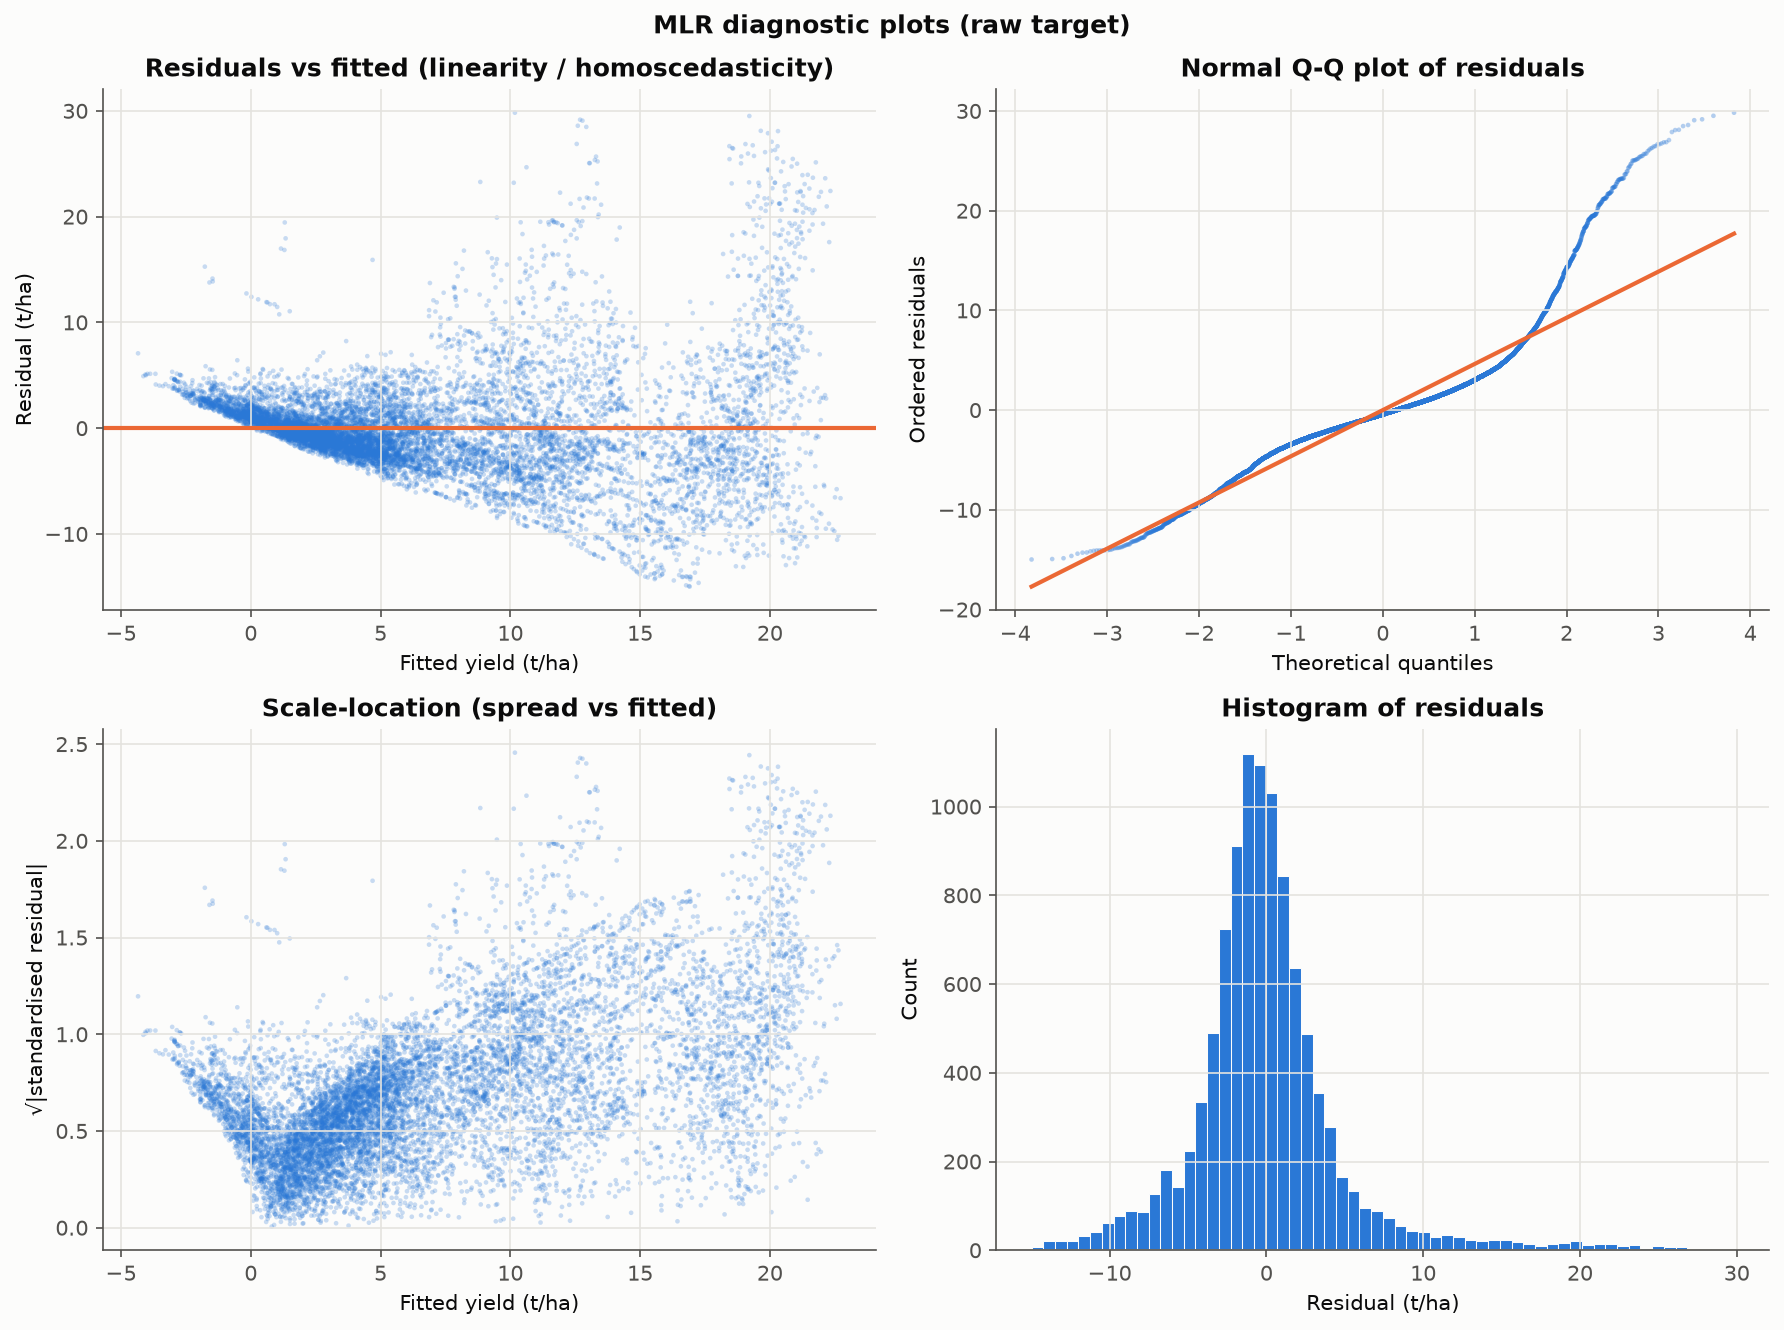

  [figure saved] outputs/figures/09_residuals_vs_predictors.png


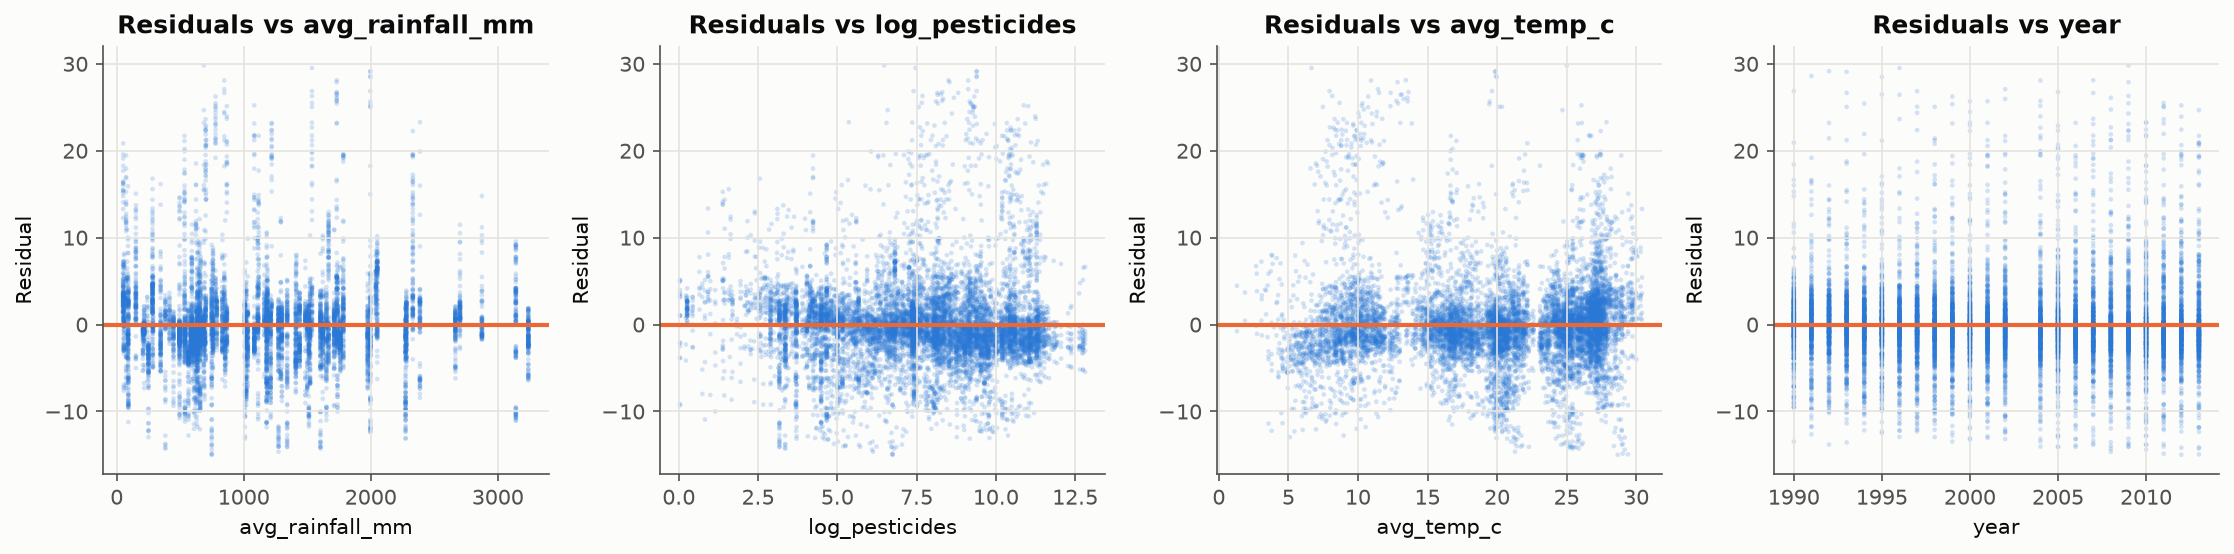


--- MLR on log(yield)  [corrective model] ---
           rainbow_F: 1.05257
           rainbow_p: 0.0317965
           shapiro_W: 0.956721
           shapiro_p: 3.67266e-36
                  jb: 7263.22
                jb_p: 0
          resid_skew: -0.777094
      resid_kurtosis: 6.76561
               bp_LM: 300.263
                bp_p: 2.11925e-56
                bp_F: 23.7451
              bp_F_p: 2.89827e-57
     dw_random_order: 2.04159
      dw_panel_order: 0.251524

Log-model R² (log scale, train) = 0.6885; smearing factor = 1.1981
Log-model test metrics on t/ha scale: {'R2': 0.6472, 'MAE': 2.9381, 'MSE': 22.6927, 'RMSE': 4.7637}


  [figure saved] outputs/figures/10_mlr_diagnostics_log.png


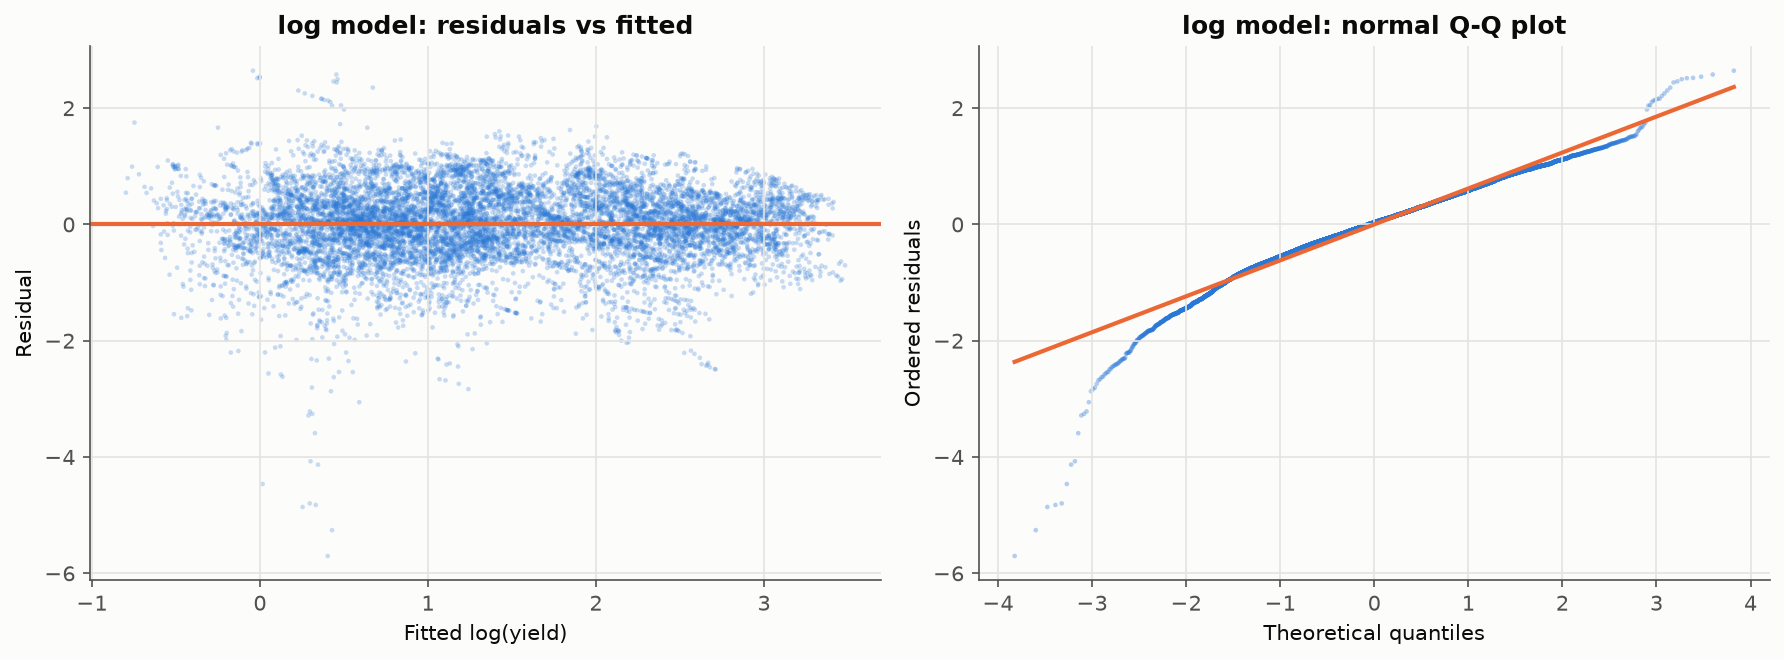


Standard errors: classical vs heteroscedasticity-robust (HC3) vs clustered by country:
                    coef  OLS_se  HC3_se  cluster_country_se  OLS_p  HC3_p  cluster_p
avg_rainfall_mm -0.0002  0.0001  0.0001              0.0004 0.0066 0.0067     0.6199
log_pesticides   0.5733  0.0207  0.0188              0.0861 0.0000 0.0000     0.0000
avg_temp_c      -0.1537  0.0088  0.0091              0.0474 0.0000 0.0000     0.0012
year             0.0842  0.0069  0.0068              0.0126 0.0000 0.0000     0.0000


In [8]:
section("7. REGRESSION ASSUMPTION TESTING (MLR, training data)")


def assumption_tests(model, data, label):
    resid, fitted = model.resid, model.fittedvalues
    out = {}
    # Linearity: Rainbow test (H0: the relationship is linear)
    rb_f, rb_p = linear_rainbow(model)
    out["rainbow_F"], out["rainbow_p"] = float(rb_f), float(rb_p)
    # Normality: Shapiro-Wilk (on a random 5,000 subsample - the test is only defined
    # up to n=5000 in SciPy) and Jarque-Bera on all residuals. H0: residuals ~ Normal
    sample = resid.sample(n=min(5000, len(resid)), random_state=SEED)
    sw = stats.shapiro(sample)
    jb, jb_p, skew, kurt = jarque_bera(resid)
    out.update({"shapiro_W": float(sw.statistic), "shapiro_p": float(sw.pvalue),
                "jb": float(jb), "jb_p": float(jb_p), "resid_skew": float(skew),
                "resid_kurtosis": float(kurt)})
    # Homoscedasticity: Breusch-Pagan (H0: constant error variance)
    lm, lm_p, f, f_p = het_breuschpagan(resid, model.model.exog)
    out.update({"bp_LM": float(lm), "bp_p": float(lm_p), "bp_F": float(f), "bp_F_p": float(f_p)})
    # Independence: Durbin-Watson (H0: no first-order autocorrelation; DW ~ 2)
    out["dw_random_order"] = float(durbin_watson(resid))
    ordered = resid.loc[data.sort_values(["country", "crop", "year"]).index]
    out["dw_panel_order"] = float(durbin_watson(ordered))
    print(f"\n--- {label} ---")
    for k, v in out.items():
        print(f"  {k:>18}: {v:.6g}")
    return out


assume_raw = assumption_tests(mlr, train_df, "MLR on raw yield (t/ha)")

# Multicollinearity: VIF on the MLR design matrix (constant excluded from report)
exog = pd.DataFrame(mlr.model.exog, columns=mlr.model.exog_names)
vif = pd.DataFrame({"feature": exog.columns,
                    "VIF": [variance_inflation_factor(exog.values, i) for i in range(exog.shape[1])]})
vif = vif[vif.feature != "Intercept"].reset_index(drop=True)
print("\nVariance Inflation Factors:\n", vif.round(3).to_string(index=False))
vif.to_csv(TAB / "vif.csv", index=False)

# Diagnostic plots
resid, fitted = mlr.resid, mlr.fittedvalues
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
ax = axes[0, 0]
ax.scatter(fitted, resid, s=5, alpha=0.25, color=BLUE, edgecolors="none")
ax.axhline(0, color=ORANGE)
ax.set(title="Residuals vs fitted (linearity / homoscedasticity)",
       xlabel="Fitted yield (t/ha)", ylabel="Residual (t/ha)")
ax = axes[0, 1]
(osm, osr), (slope, intercept, _) = stats.probplot(resid, dist="norm")
ax.scatter(osm, osr, s=5, alpha=0.35, color=BLUE, edgecolors="none")
ax.plot(osm, slope * osm + intercept, color=ORANGE)
ax.set(title="Normal Q-Q plot of residuals", xlabel="Theoretical quantiles",
       ylabel="Ordered residuals")
ax = axes[1, 0]
ax.scatter(fitted, np.sqrt(np.abs(resid / resid.std())), s=5, alpha=0.25, color=BLUE,
           edgecolors="none")
ax.set(title="Scale-location (spread vs fitted)", xlabel="Fitted yield (t/ha)",
       ylabel="√|standardised residual|")
ax = axes[1, 1]
ax.hist(resid, bins=60, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
ax.set(title="Histogram of residuals", xlabel="Residual (t/ha)", ylabel="Count")
fig.suptitle("MLR diagnostic plots (raw target)", fontweight="bold")
plt.tight_layout()
savefig("08_mlr_diagnostics_raw")

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, c in zip(axes, NUM):
    ax.scatter(train_df[c], resid, s=5, alpha=0.2, color=BLUE, edgecolors="none")
    ax.axhline(0, color=ORANGE)
    ax.set(title=f"Residuals vs {c}", xlabel=c, ylabel="Residual")
plt.tight_layout()
savefig("09_residuals_vs_predictors")

# Corrective measure 1: log-transform the target (multiplicative crop effects)
mlr_log = smf.ols(MLR_FORMULA.replace(TARGET, f"np.log({TARGET})"), data=train_df).fit()
assume_log = assumption_tests(mlr_log, train_df, "MLR on log(yield)  [corrective model]")
# Back-transform with Duan's smearing estimator so predictions are on the t/ha scale
smear = float(np.mean(np.exp(mlr_log.resid)))
mlr_log_pred = np.exp(mlr_log.predict(test_df)) * smear
mlr_log_test = metrics(y_test, mlr_log_pred)
print(f"\nLog-model R² (log scale, train) = {mlr_log.rsquared:.4f}; smearing factor = {smear:.4f}")
print("Log-model test metrics on t/ha scale:", {k: round(v, 4) for k, v in mlr_log_test.items()})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(mlr_log.fittedvalues, mlr_log.resid, s=5, alpha=0.25, color=BLUE, edgecolors="none")
axes[0].axhline(0, color=ORANGE)
axes[0].set(title="log model: residuals vs fitted", xlabel="Fitted log(yield)", ylabel="Residual")
(osm, osr), (slope, intercept, _) = stats.probplot(mlr_log.resid, dist="norm")
axes[1].scatter(osm, osr, s=5, alpha=0.35, color=BLUE, edgecolors="none")
axes[1].plot(osm, slope * osm + intercept, color=ORANGE)
axes[1].set(title="log model: normal Q-Q plot", xlabel="Theoretical quantiles", ylabel="Ordered residuals")
plt.tight_layout()
savefig("10_mlr_diagnostics_log")

# Corrective measure 2: robust standard errors (inference only; coefficients unchanged)
hc3 = mlr.get_robustcov_results(cov_type="HC3")
clus = smf.ols(MLR_FORMULA, data=train_df).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(train_df["country"])[0]})
se_cmp = pd.DataFrame({"coef": mlr.params, "OLS_se": mlr.bse,
                       "HC3_se": pd.Series(hc3.bse, index=mlr.params.index),
                       "cluster_country_se": clus.bse, "OLS_p": mlr.pvalues,
                       "HC3_p": pd.Series(hc3.pvalues, index=mlr.params.index),
                       "cluster_p": clus.pvalues})
print("\nStandard errors: classical vs heteroscedasticity-robust (HC3) vs clustered by country:\n",
      se_cmp.loc[NUM].round(5).to_string())
se_cmp.to_csv(TAB / "mlr_robust_standard_errors.csv")

RESULTS["assumptions"] = {"raw": assume_raw, "log": assume_log,
                          "vif": vif.set_index("feature")["VIF"].round(3).to_dict(),
                          "log_model": {"r2_log_train": mlr_log.rsquared, "smear": smear,
                                        "test": mlr_log_test,
                                        "coef": mlr_log.params.round(6).to_dict(),
                                        "p": mlr_log.pvalues.to_dict()},
                          "robust_se": se_cmp.loc[NUM].round(6).to_dict(orient="index")}

## 8. Estimator validation: K-fold CV and bootstrap


8. ESTIMATOR VALIDATION (K-FOLD CV AND BOOTSTRAP)


Per-fold validation metrics:
 model  fold     R2    MAE     MSE   RMSE
  SLR     1 0.0332 5.6705 58.1330 7.6245
  MLR     1 0.6117 3.1682 23.3493 4.8321
  SLR     2 0.0215 5.5698 56.5672 7.5211
  MLR     2 0.6098 3.1149 22.5578 4.7495
  SLR     3 0.0337 5.7737 62.1055 7.8807
  MLR     3 0.6000 3.2763 25.7072 5.0702
  SLR     4 0.0407 5.6933 60.0833 7.7513
  MLR     4 0.6188 3.2244 23.8792 4.8866
  SLR     5 0.0341 5.7946 63.6087 7.9755
  MLR     5 0.5869 3.3498 27.2067 5.2160

CV summary (mean, std):
           R2           MAE            MSE          RMSE       
        mean    std   mean    std    mean    std   mean    std
model                                                         
MLR   0.6054 0.0123 3.2267 0.0916 24.5400 1.8879 4.9509 0.1893
SLR   0.0327 0.0070 5.7004 0.0898 60.0996 2.8585 7.7506 0.1844

MLR numeric coefficients per fold:
  fold  num__avg_rainfall_mm  num__log_pesticides  num__avg_temp_c  num__year
    1               -0.0001               0.5753          -0.158


Bootstrap (row B=1000, country-cluster B=500) coefficient distribution:
                coefficient  OLS_estimate  boot_mean  boot_se  OLS_se   ci2.5  ci97.5  pct_positive  cluster_boot_se  cluster_ci2.5  cluster_ci97.5
           avg_rainfall_mm       -0.0002    -0.0002   0.0001  0.0001 -0.0003 -0.0001        0.5000           0.0004        -0.0010          0.0007
            log_pesticides        0.5733     0.5732   0.0186  0.0207  0.5376  0.6116      100.0000           0.0878         0.4118          0.7448
                avg_temp_c       -0.1537    -0.1535   0.0091  0.0088 -0.1706 -0.1364        0.0000           0.0472        -0.2462         -0.0587
                      year        0.0842     0.0847   0.0066  0.0069  0.0725  0.0969      100.0000           0.0119         0.0623          0.1085
SLR slope (log_pesticides)        0.5598     0.5588   0.0270  0.0293  0.5068  0.6096      100.0000              NaN            NaN             NaN

Bootstrap out-of-bag performance:
         

  [figure saved] outputs/figures/11_bootstrap_distributions.png


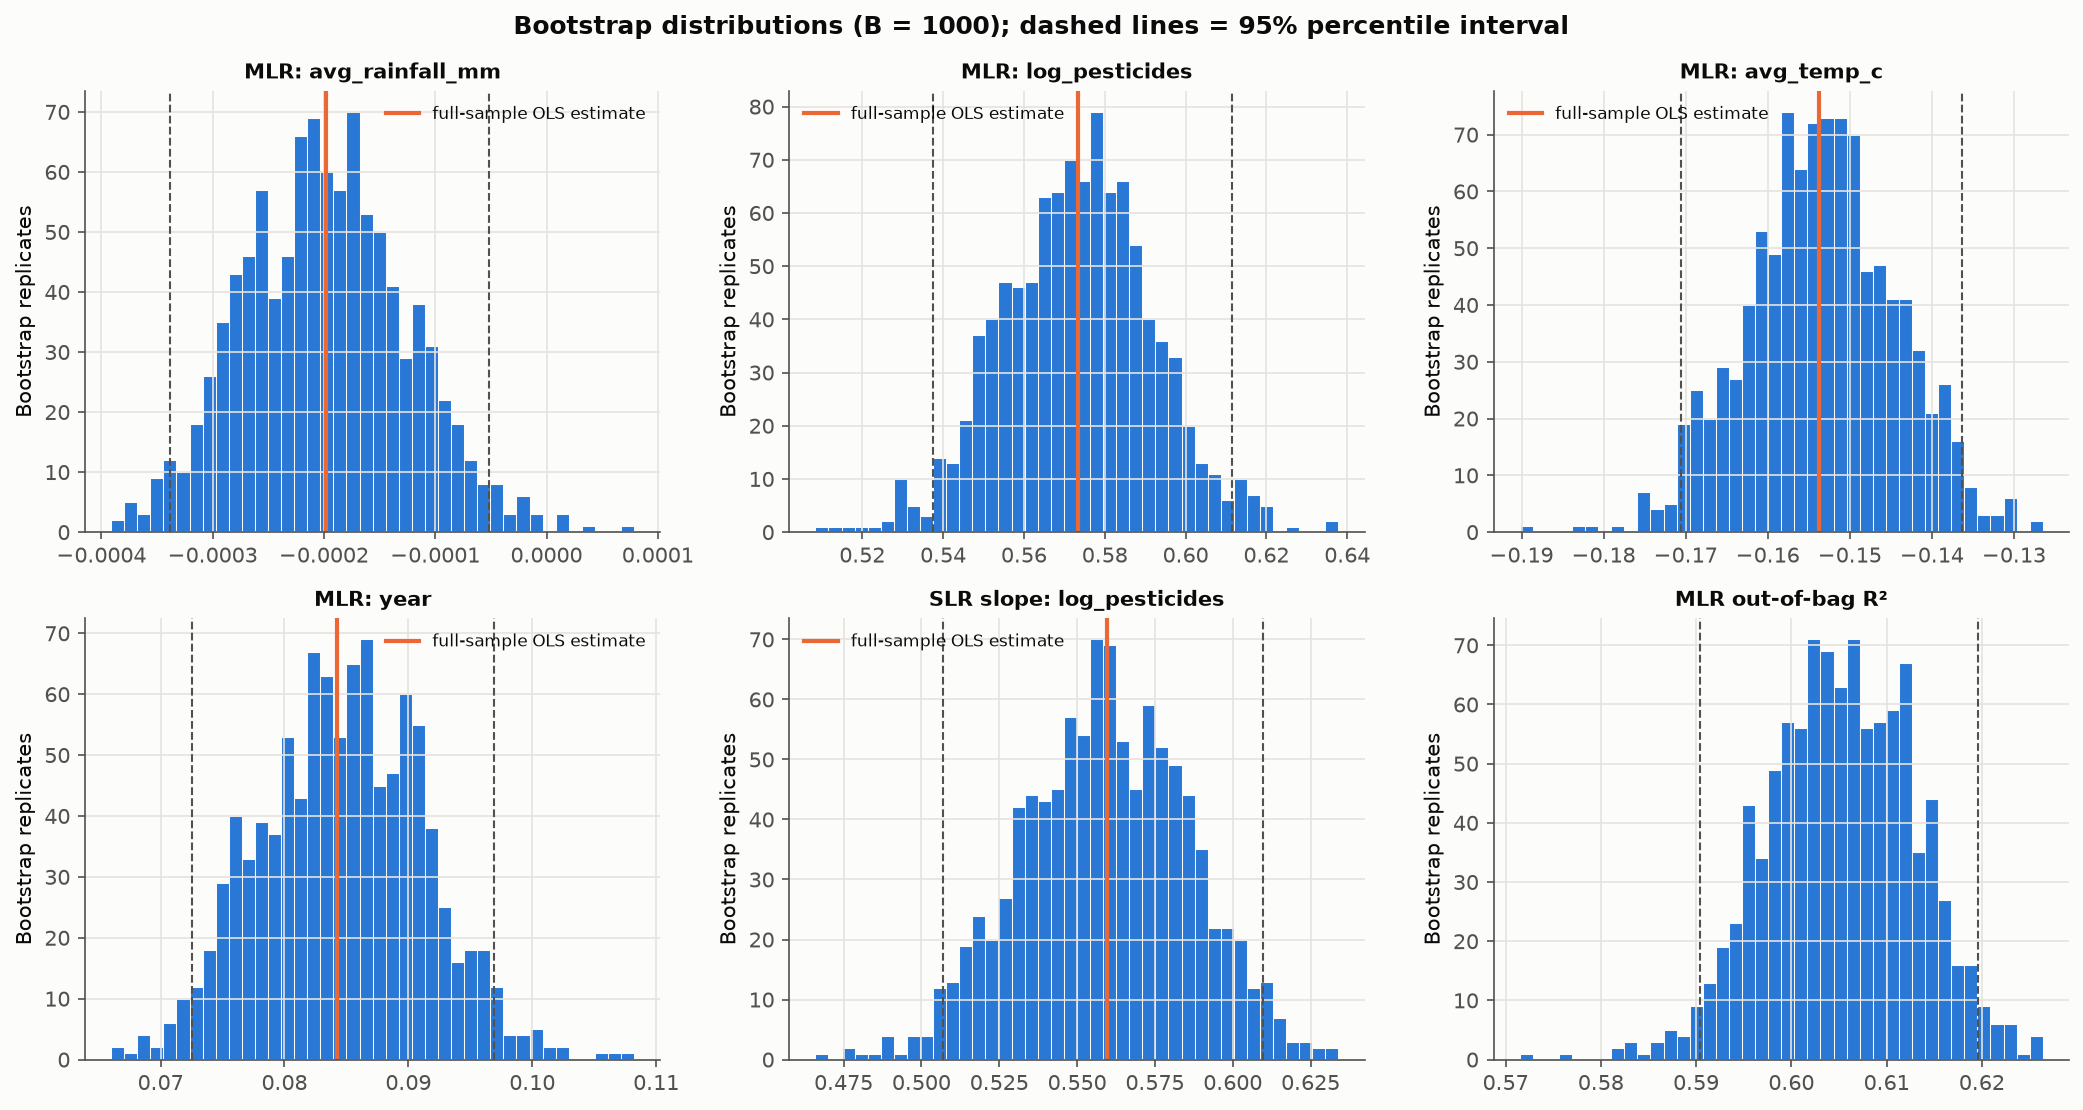

  [figure saved] outputs/figures/12_cv_r2_phase1.png


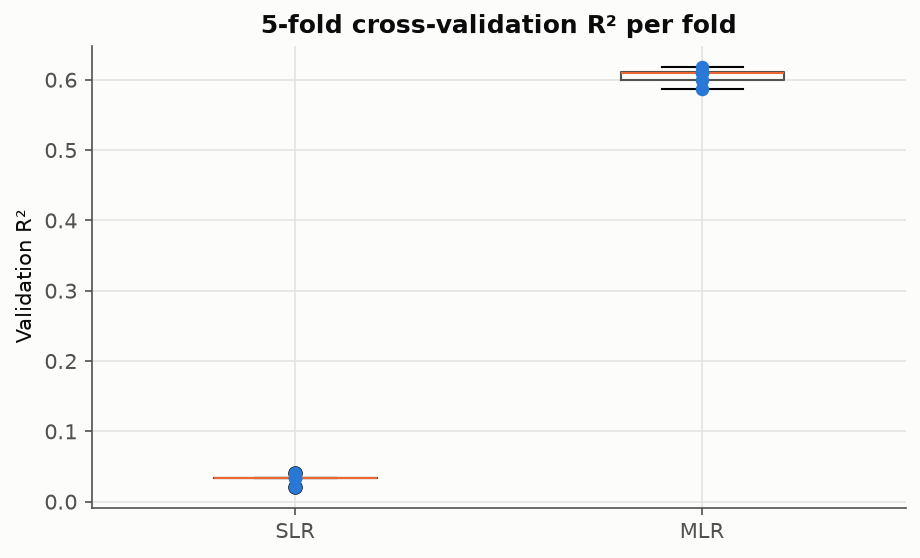

In [9]:
section("8. ESTIMATOR VALIDATION (K-FOLD CV AND BOOTSTRAP)")
# sklearn equivalents of the Phase 1 models (identical design matrices)
slr_pipe = Pipeline([("sel", ColumnTransformer([("x", "passthrough", [slr_x])])),
                     ("lr", LinearRegression())])
mlr_pipe = Pipeline([("prep", ColumnTransformer([
    ("num", "passthrough", NUM),
    ("crop", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), ["crop"])])),
    ("lr", LinearRegression())])

fold_rows, coef_rows = [], []
for k, (tr, va) in enumerate(CV.split(X_train), start=1):
    for name, pipe in [("SLR", slr_pipe), ("MLR", mlr_pipe)]:
        m = clone(pipe).fit(X_train.iloc[tr], y_train.iloc[tr])
        fold_rows.append({"model": name, "fold": k, **metrics(y_train.iloc[va], m.predict(X_train.iloc[va]))})
        lr = m.named_steps["lr"]
        coefs = dict(zip(m.named_steps[list(m.named_steps)[0]].get_feature_names_out(), lr.coef_))
        coef_rows.append({"model": name, "fold": k, "intercept": lr.intercept_, **coefs})
cv_folds = pd.DataFrame(fold_rows)
cv_coefs = pd.DataFrame(coef_rows)
print("Per-fold validation metrics:\n", cv_folds.round(4).to_string(index=False))
cv_summary = cv_folds.groupby("model")[["R2", "MAE", "MSE", "RMSE"]].agg(["mean", "std"])
print("\nCV summary (mean, std):\n", cv_summary.round(4).to_string())
mlr_fold_coef = cv_coefs[cv_coefs.model == "MLR"][["fold"] + [f"num__{c}" for c in NUM]]
print("\nMLR numeric coefficients per fold:\n", mlr_fold_coef.round(5).to_string(index=False))
cv_folds.to_csv(TAB / "phase1_cv_folds.csv", index=False)
cv_coefs.to_csv(TAB / "phase1_cv_coefficients.csv", index=False)

# Bootstrap: resample training rows with replacement, refit, record coefficients and
# out-of-bag (OOB) performance on rows not drawn in that resample.
B = 1000
rng = np.random.default_rng(SEED)
Xd = mlr_pipe.named_steps["prep"].fit(X_train).transform(X_train)
Xd = np.column_stack([np.ones(len(Xd)), Xd])
names = ["intercept"] + list(mlr_pipe.named_steps["prep"].get_feature_names_out())
xs_slr = np.column_stack([np.ones(len(X_train)), X_train[slr_x].values])
yv = y_train.values
n = len(yv)
boot_coef, boot_slr, boot_perf = [], [], []
for b in range(B):
    idx = rng.integers(0, n, n)
    oob = np.setdiff1d(np.arange(n), idx)
    beta = np.linalg.lstsq(Xd[idx], yv[idx], rcond=None)[0]
    beta_s = np.linalg.lstsq(xs_slr[idx], yv[idx], rcond=None)[0]
    boot_coef.append(beta)
    boot_slr.append(beta_s)
    boot_perf.append({"MLR_" + k: v for k, v in metrics(yv[oob], Xd[oob] @ beta).items()} |
                     {"SLR_" + k: v for k, v in metrics(yv[oob], xs_slr[oob] @ beta_s).items()})
boot_coef = pd.DataFrame(boot_coef, columns=names)
boot_slr = pd.DataFrame(boot_slr, columns=["b0", "b1"])
boot_perf = pd.DataFrame(boot_perf)

ols_map = {f"num__{c}": c for c in NUM}
boot_tab = []
for col in [f"num__{c}" for c in NUM]:
    s = boot_coef[col]
    boot_tab.append({"coefficient": ols_map[col], "OLS_estimate": mlr.params[ols_map[col]],
                     "boot_mean": s.mean(), "boot_se": s.std(ddof=1),
                     "OLS_se": mlr.bse[ols_map[col]], "ci2.5": s.quantile(0.025),
                     "ci97.5": s.quantile(0.975), "pct_positive": 100 * (s > 0).mean()})
boot_tab.append({"coefficient": f"SLR slope ({slr_x})", "OLS_estimate": slr.params[slr_x],
                 "boot_mean": boot_slr.b1.mean(), "boot_se": boot_slr.b1.std(ddof=1),
                 "OLS_se": slr.bse[slr_x], "ci2.5": boot_slr.b1.quantile(0.025),
                 "ci97.5": boot_slr.b1.quantile(0.975),
                 "pct_positive": 100 * (boot_slr.b1 > 0).mean()})
boot_tab = pd.DataFrame(boot_tab)

# Cluster (block) bootstrap: resample whole COUNTRIES with replacement. Rows of the same
# country are serially correlated (panel Durbin-Watson << 2), so the row bootstrap above
# treats them as independent and understates uncertainty.
countries = X_train["country"].values
uniq = np.unique(countries)
rows_by_c = {c: np.where(countries == c)[0] for c in uniq}
B_CL = 500
cl_coef = []
for b in range(B_CL):
    pick = rng.choice(uniq, size=len(uniq), replace=True)
    idx = np.concatenate([rows_by_c[c] for c in pick])
    cl_coef.append(np.linalg.lstsq(Xd[idx], yv[idx], rcond=None)[0])
cl_coef = pd.DataFrame(cl_coef, columns=names)
boot_tab["cluster_boot_se"] = [cl_coef[f"num__{c}"].std(ddof=1) for c in NUM] + [np.nan]
boot_tab["cluster_ci2.5"] = [cl_coef[f"num__{c}"].quantile(0.025) for c in NUM] + [np.nan]
boot_tab["cluster_ci97.5"] = [cl_coef[f"num__{c}"].quantile(0.975) for c in NUM] + [np.nan]
print(f"\nBootstrap (row B={B}, country-cluster B={B_CL}) coefficient distribution:\n",
      boot_tab.round(5).to_string(index=False))
perf_sum = boot_perf.agg(["mean", "std"]).T
perf_sum["ci2.5"] = boot_perf.quantile(0.025)
perf_sum["ci97.5"] = boot_perf.quantile(0.975)
print("\nBootstrap out-of-bag performance:\n", perf_sum.round(4).to_string())
boot_tab.to_csv(TAB / "bootstrap_coefficients.csv", index=False)
perf_sum.to_csv(TAB / "bootstrap_oob_performance.csv")

fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
plot_items = [(boot_coef[f"num__{c}"], f"MLR: {c}", mlr.params[c]) for c in NUM] + \
             [(boot_slr.b1, f"SLR slope: {slr_x}", slr.params[slr_x]),
              (boot_perf["MLR_R2"], "MLR out-of-bag R²", None)]
for ax, (s, title, est) in zip(axes.ravel(), plot_items):
    ax.hist(s, bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
    lo, hi = s.quantile([0.025, 0.975])
    for v in (lo, hi):
        ax.axvline(v, color=INK2, linestyle="--", linewidth=1)
    if est is not None:
        ax.axvline(est, color=ORANGE, label="full-sample OLS estimate")
        ax.legend(frameon=False, fontsize=8)
    ax.set_title(title, fontsize=10)
    ax.set_ylabel("Bootstrap replicates")
fig.suptitle(f"Bootstrap distributions (B = {B}); dashed lines = 95% percentile interval",
             fontweight="bold")
plt.tight_layout()
savefig("11_bootstrap_distributions")

fig, ax = plt.subplots(figsize=(7, 4))
data_box = [cv_folds[cv_folds.model == m]["R2"] for m in ["SLR", "MLR"]]
ax.boxplot(data_box, tick_labels=["SLR", "MLR"], widths=0.4,
           medianprops={"color": ORANGE}, boxprops={"color": INK2})
for i, d in enumerate(data_box, start=1):
    ax.scatter(np.full(len(d), i), d, color=BLUE, s=30, zorder=3)
ax.set(title="5-fold cross-validation R² per fold", ylabel="Validation R²")
savefig("12_cv_r2_phase1")

RESULTS["validation"] = {"cv_summary": {m: {met: {"mean": float(cv_summary.loc[m, (met, "mean")]),
                                                  "std": float(cv_summary.loc[m, (met, "std")])}
                                            for met in ["R2", "MAE", "MSE", "RMSE"]}
                                        for m in ["SLR", "MLR"]},
                         "cv_folds": cv_folds.round(5).to_dict(orient="records"),
                         "mlr_fold_coefs": mlr_fold_coef.round(6).to_dict(orient="records"),
                         "bootstrap_B": B, "cluster_bootstrap_B": B_CL, "bootstrap": boot_tab.round(6).to_dict(orient="records"),
                         "bootstrap_perf": perf_sum.round(5).to_dict(orient="index")}

## 9. Phase 2 - Feature selection (training data only)


9. PHASE 2: FEATURE SELECTION (training data only)
Correlation / association with yield (train):
         feature        type  pearson_r  spearman_rho  eta_squared
avg_rainfall_mm     numeric     0.0168        0.0750          NaN
 log_pesticides     numeric     0.1832        0.2148          NaN
     avg_temp_c     numeric    -0.1401       -0.1030          NaN
           year     numeric     0.0879        0.0867          NaN
           crop categorical        NaN           NaN       0.5343
        country categorical        NaN           NaN       0.2055



RFECV (19.4s): optimal number of encoded columns = 110 of 115
Encoded columns kept by RFECV per original feature:
                  kept  total
avg_rainfall_mm     1      1
avg_temp_c          1      1
country            97    101
crop               10     10
log_pesticides      0      1
year                1      1
Columns eliminated by RFECV: ['num__log_pesticides', 'cat__country_Brazil', 'cat__country_Hungary', 'cat__country_Morocco', 'cat__country_Niger']


  [figure saved] outputs/figures/13_rfecv_curve.png


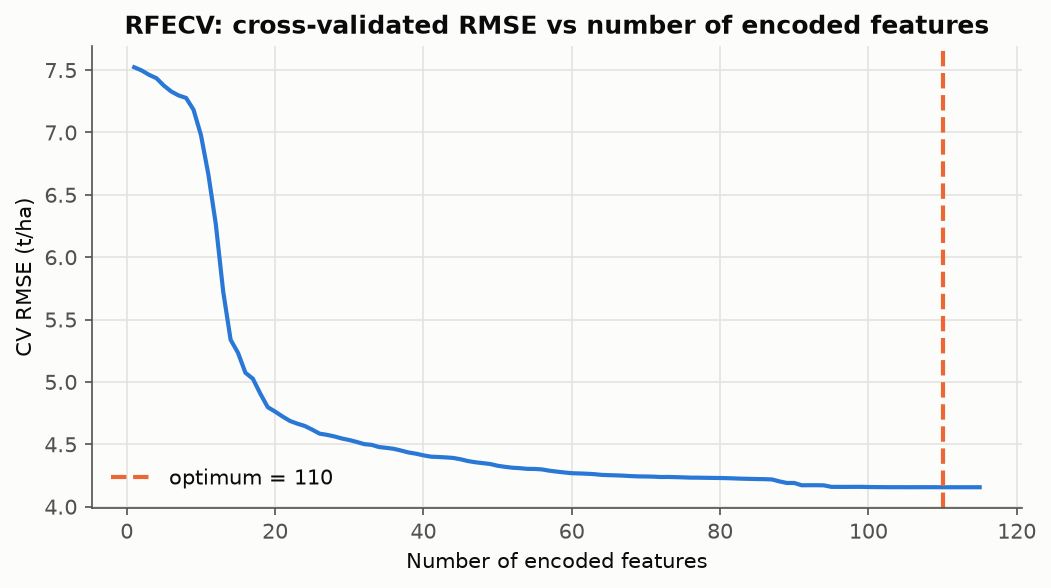


Random Forest impurity importance (grouped by original feature):
 crop              0.5365
country           0.1328
log_pesticides    0.1190
avg_rainfall_mm   0.0943
avg_temp_c        0.0861
year              0.0314

Permutation importance (drop in validation R² when the feature is shuffled):
                  perm_importance_mean  perm_importance_std
crop                           1.4850               0.0387
avg_temp_c                     0.2815               0.0176
avg_rainfall_mm                0.2700               0.0098
log_pesticides                 0.2043               0.0115
country                        0.1704               0.0110
year                           0.0506               0.0066


  [figure saved] outputs/figures/14_feature_importance.png


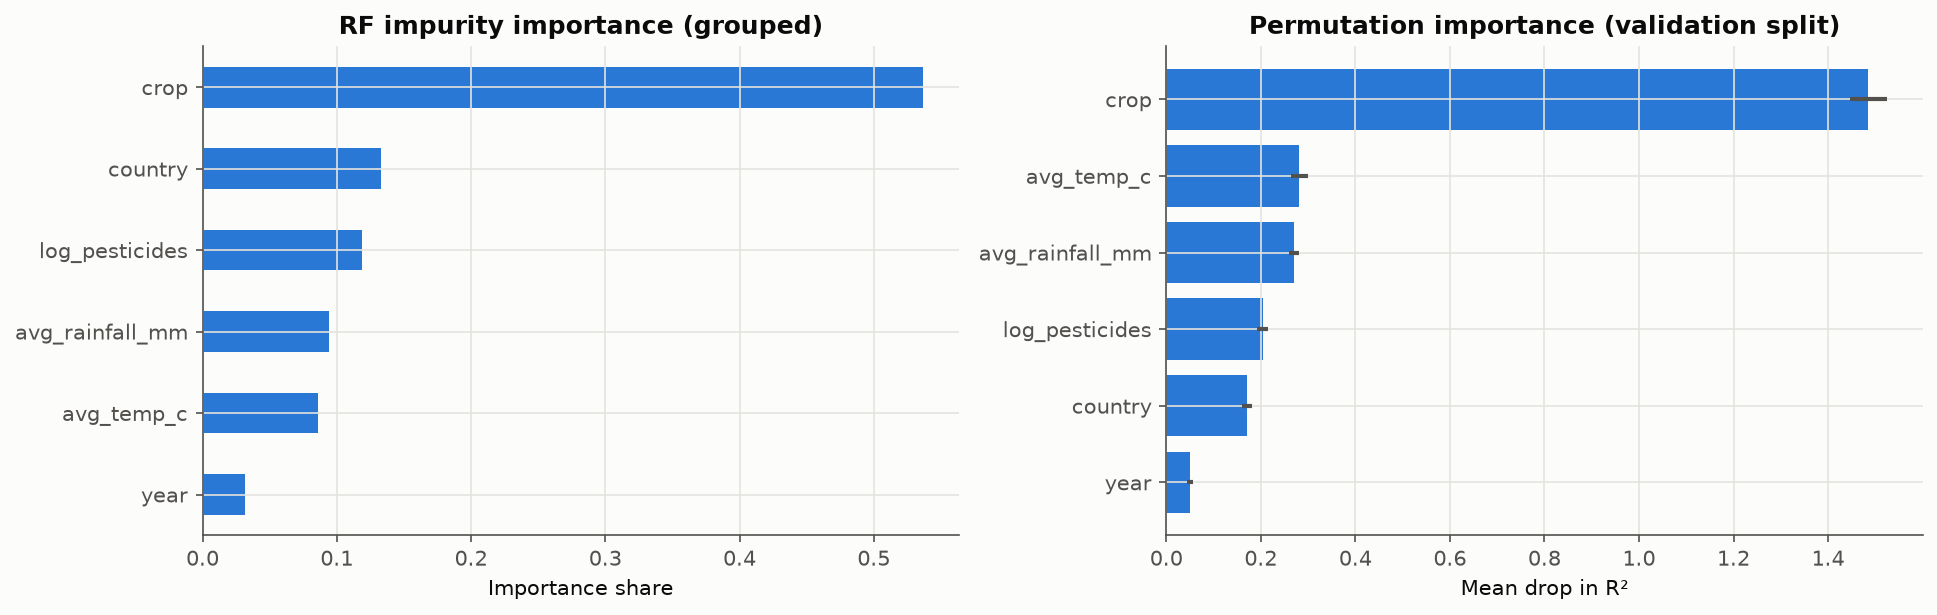


Selected features for Phase 2 models: ['avg_rainfall_mm', 'log_pesticides', 'avg_temp_c', 'year', 'crop', 'country']
Dropped: []


In [10]:
section("9. PHASE 2: FEATURE SELECTION (training data only)")


def make_prep(num, cat, scale=True):
    parts = []
    if num:
        parts.append(("num", StandardScaler() if scale else "passthrough", num))
    if cat:
        parts.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat))
    return ColumnTransformer(parts)


# (a) Correlation / association based
fs_rows = []
for c in NUM:
    fs_rows.append({"feature": c, "type": "numeric",
                    "pearson_r": train_df[c].corr(train_df[TARGET]),
                    "spearman_rho": train_df[c].corr(train_df[TARGET], method="spearman"),
                    "eta_squared": np.nan})
for c in CAT:
    fs_rows.append({"feature": c, "type": "categorical", "pearson_r": np.nan, "spearman_rho": np.nan,
                    "eta_squared": eta_squared(train_df[c], train_df[TARGET])})
fs_corr = pd.DataFrame(fs_rows)
print("Correlation / association with yield (train):\n", fs_corr.round(4).to_string(index=False))

# (b) Recursive Feature Elimination with CV (linear model on the one-hot design)
prep_full = make_prep(NUM, CAT).fit(X_train)
Xt_full = prep_full.transform(X_train)
fnames = prep_full.get_feature_names_out()
t0 = time.time()
rfecv = RFECV(LinearRegression(), step=1, cv=CV, scoring="neg_root_mean_squared_error",
              min_features_to_select=1, n_jobs=N_JOBS).fit(Xt_full, y_train)
print(f"\nRFECV ({time.time() - t0:.1f}s): optimal number of encoded columns = "
      f"{rfecv.n_features_} of {len(fnames)}")
rfe_sel = pd.Series(rfecv.support_, index=fnames)
grp = pd.Series([f.split("__")[1].split("_")[0] if f.startswith("cat__") else f.split("__")[1]
                 for f in fnames], index=fnames)
grp = grp.replace({"crop": "crop", "country": "country"})
rfe_group = pd.DataFrame({"kept": rfe_sel.groupby(grp).sum(), "total": rfe_sel.groupby(grp).size()})
print("Encoded columns kept by RFECV per original feature:\n", rfe_group.to_string())
rfe_dropped = [f for f, s in rfe_sel.items() if not s]
print("Columns eliminated by RFECV:", rfe_dropped)
cv_scores = -rfecv.cv_results_["mean_test_score"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, len(cv_scores) + 1), cv_scores, color=BLUE)
ax.axvline(rfecv.n_features_, color=ORANGE, linestyle="--", label=f"optimum = {rfecv.n_features_}")
ax.set(title="RFECV: cross-validated RMSE vs number of encoded features",
       xlabel="Number of encoded features", ylabel="CV RMSE (t/ha)")
ax.legend(frameon=False)
savefig("13_rfecv_curve")

# (c) Model-based importance: Random Forest + grouped permutation importance on an
#     internal validation split carved out of the training set.
fs_tr, fs_va = train_test_split(train_df, test_size=0.2, random_state=SEED)
rf_fs = Pipeline([("prep", make_prep(NUM, CAT, scale=False)),
                  ("rf", RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=N_JOBS))])
rf_fs.fit(fs_tr[ALL_FEATURES], fs_tr[TARGET])
imp = pd.Series(rf_fs.named_steps["rf"].feature_importances_,
                index=rf_fs.named_steps["prep"].get_feature_names_out())
imp_grp = imp.groupby([n.split("__")[1].split("_")[0] if n.startswith("cat__") else n.split("__")[1]
                       for n in imp.index]).sum().sort_values(ascending=False)
perm = permutation_importance(rf_fs, fs_va[ALL_FEATURES], fs_va[TARGET], n_repeats=10,
                              random_state=SEED, scoring="r2", n_jobs=N_JOBS)
perm_s = pd.DataFrame({"perm_importance_mean": perm.importances_mean,
                       "perm_importance_std": perm.importances_std}, index=ALL_FEATURES) \
           .sort_values("perm_importance_mean", ascending=False)
print("\nRandom Forest impurity importance (grouped by original feature):\n", imp_grp.round(4).to_string())
print("\nPermutation importance (drop in validation R² when the feature is shuffled):\n",
      perm_s.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
imp_grp.sort_values().plot.barh(ax=axes[0], color=BLUE)
axes[0].set(title="RF impurity importance (grouped)", xlabel="Importance share")
ps = perm_s["perm_importance_mean"].sort_values()
axes[1].barh(ps.index, ps.values, xerr=perm_s.loc[ps.index, "perm_importance_std"], color=BLUE,
             ecolor=INK2)
axes[1].set(title="Permutation importance (validation split)", xlabel="Mean drop in R²")
plt.tight_layout()
savefig("14_feature_importance")

# Decision rule (fixed in advance): keep an original feature if shuffling it lowers
# validation R² by more than 0.001.
SELECTED = [f for f in ALL_FEATURES if perm_s.loc[f, "perm_importance_mean"] > 0.001]
SEL_NUM = [f for f in NUM if f in SELECTED]
SEL_CAT = [f for f in CAT if f in SELECTED]
print(f"\nSelected features for Phase 2 models: {SELECTED}")
print(f"Dropped: {[f for f in ALL_FEATURES if f not in SELECTED]}")

fs_table = fs_corr.set_index("feature").join(imp_grp.rename("rf_impurity_importance")) \
                  .join(perm_s).join(rfe_group)
fs_table["selected"] = fs_table.index.isin(SELECTED)
fs_table.to_csv(TAB / "feature_selection_summary.csv")
RESULTS["feature_selection"] = {"table": fs_table.round(5).reset_index().to_dict(orient="records"),
                                "rfecv_n": int(rfecv.n_features_), "rfecv_total": int(len(fnames)),
                                "rfecv_dropped": rfe_dropped, "selected": SELECTED}

## 10. Ridge and LASSO


10. RIDGE (L2) AND LASSO (L1) REGRESSION


Ridge: best alpha = 0.17783, CV RMSE = 4.1557
LASSO: best alpha = 0.00015399, CV RMSE = 4.1556


  [figure saved] outputs/figures/15_ridge_lasso_alpha_tuning.png


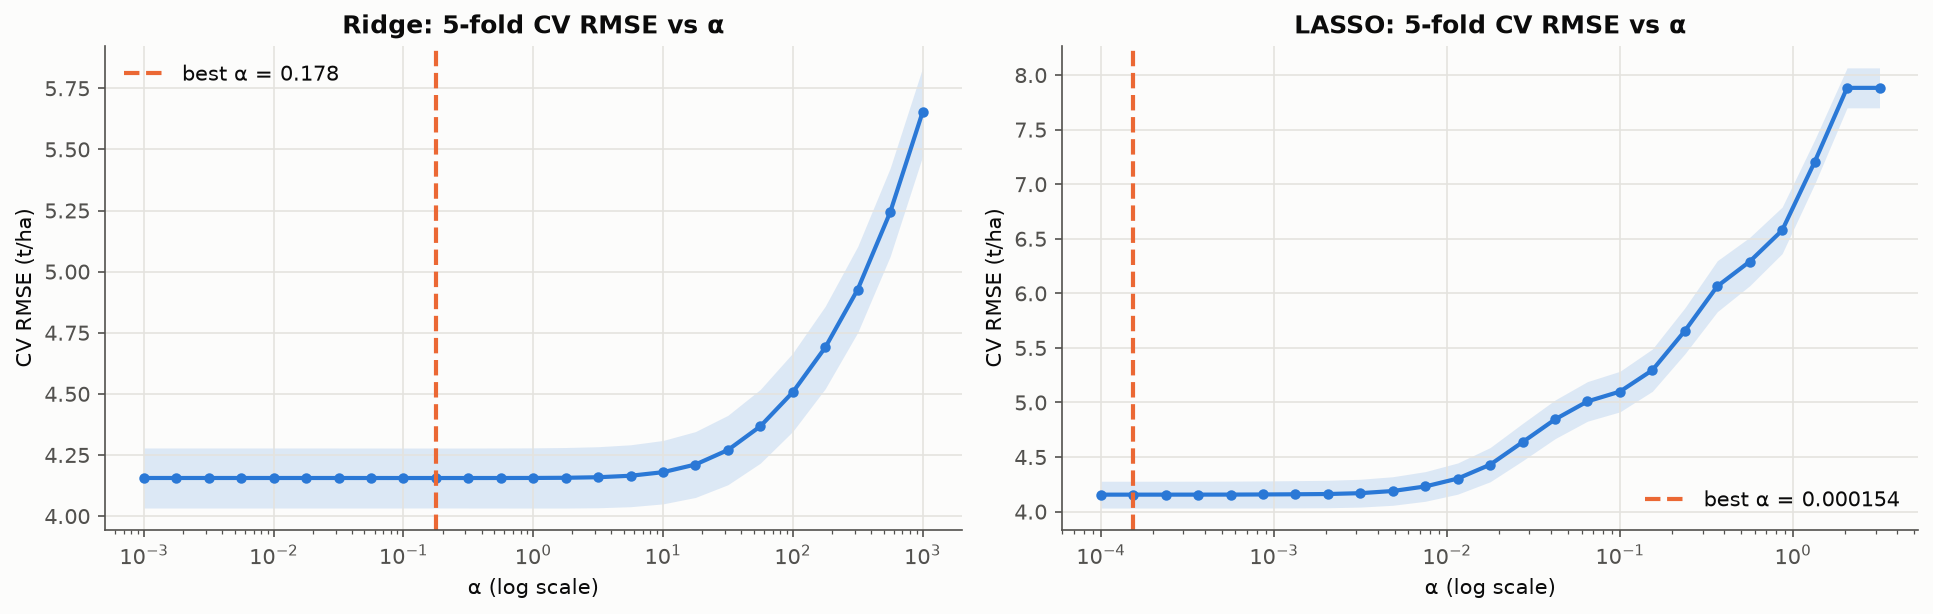


LASSO set 3 of 115 coefficients exactly to zero:
['cat__country_Albania', 'cat__country_Colombia', 'cat__country_Senegal']

Numeric-feature coefficients (per 1 SD, t/ha):
                        ridge   lasso
num__avg_rainfall_mm  0.0238 -0.0166
num__log_pesticides  -0.0830 -0.0082
num__avg_temp_c      -0.8039 -0.6681
num__year             0.7236  0.7135

Crop coefficients (t/ha, relative to the overall intercept):
                                  ridge   lasso
cat__crop_Cassava               3.9240  5.8200
cat__crop_Maize                -4.4440 -2.5460
cat__crop_Plantains and others  5.2860  7.1780
cat__crop_Potatoes              9.4350 11.3320
cat__crop_Rice, paddy          -3.5640 -1.6660
cat__crop_Sorghum              -5.2410 -3.3450
cat__crop_Soybeans             -6.6860 -4.7870
cat__crop_Sweet potatoes        2.8010  4.6990
cat__crop_Wheat                -5.9740 -4.0760
cat__crop_Yams                  4.4630  6.3560



LASSO 1-SE rule: alpha = 0.0048697, CV RMSE = 4.1890, zero coefficients = 26 of 115
Non-zero numeric coefficients under 1-SE LASSO:
 num__avg_rainfall_mm   -0.0092
num__log_pesticides     1.0370
num__avg_temp_c        -0.9423
num__year               0.6234
Crop dummies set to zero: []
Numeric features set to zero: []


  [figure saved] outputs/figures/16_lasso_path.png


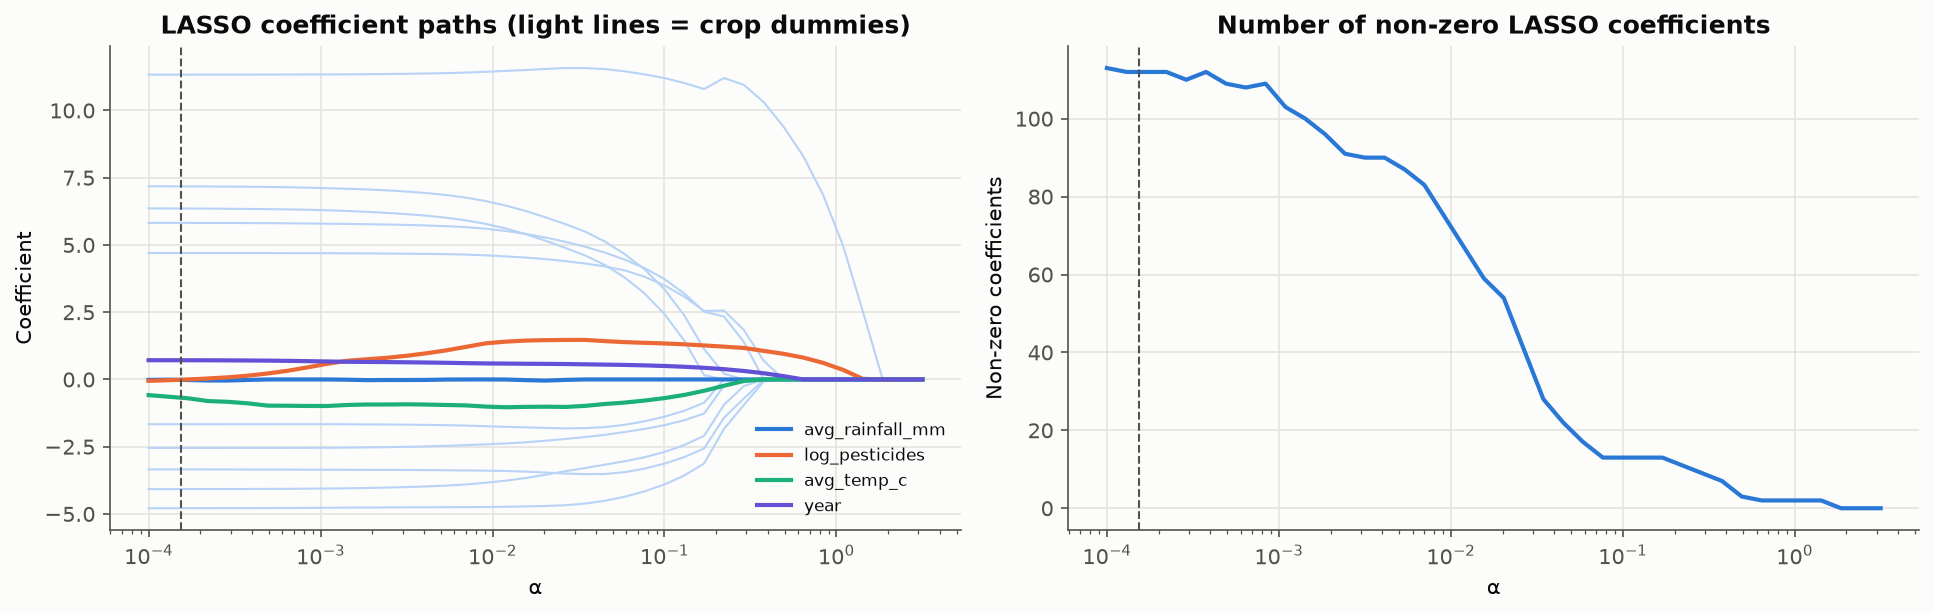

In [11]:
section("10. RIDGE (L2) AND LASSO (L1) REGRESSION")
prep_sel = make_prep(SEL_NUM, SEL_CAT)
ridge_gs = GridSearchCV(Pipeline([("prep", prep_sel), ("model", Ridge())]),
                        {"model__alpha": np.logspace(-3, 3, 25)}, cv=CV,
                        scoring="neg_root_mean_squared_error", n_jobs=N_JOBS).fit(X_train, y_train)
lasso_gs = GridSearchCV(Pipeline([("prep", prep_sel),
                                  ("model", Lasso(max_iter=50_000, random_state=SEED))]),
                        {"model__alpha": np.logspace(-4, 0.5, 25)}, cv=CV,
                        scoring="neg_root_mean_squared_error", n_jobs=N_JOBS).fit(X_train, y_train)
for name, gs in [("Ridge", ridge_gs), ("LASSO", lasso_gs)]:
    print(f"{name}: best alpha = {gs.best_params_['model__alpha']:.5g}, "
          f"CV RMSE = {-gs.best_score_:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (name, gs) in zip(axes, [("Ridge", ridge_gs), ("LASSO", lasso_gs)]):
    a = gs.cv_results_["param_model__alpha"].data.astype(float)
    m = -gs.cv_results_["mean_test_score"]
    s = gs.cv_results_["std_test_score"]
    ax.semilogx(a, m, color=BLUE, marker="o", markersize=4)
    ax.fill_between(a, m - s, m + s, color=BLUE, alpha=0.15, linewidth=0)
    ax.axvline(gs.best_params_["model__alpha"], color=ORANGE, linestyle="--",
               label=f"best α = {gs.best_params_['model__alpha']:.3g}")
    ax.set(title=f"{name}: 5-fold CV RMSE vs α", xlabel="α (log scale)", ylabel="CV RMSE (t/ha)")
    ax.legend(frameon=False)
plt.tight_layout()
savefig("15_ridge_lasso_alpha_tuning")

sel_names = ridge_gs.best_estimator_.named_steps["prep"].get_feature_names_out()
ridge_coef = pd.Series(ridge_gs.best_estimator_.named_steps["model"].coef_, index=sel_names)
lasso_coef = pd.Series(lasso_gs.best_estimator_.named_steps["model"].coef_, index=sel_names)
zeroed = lasso_coef[lasso_coef == 0].index.tolist()
print(f"\nLASSO set {len(zeroed)} of {len(lasso_coef)} coefficients exactly to zero:")
print(zeroed)
coef_cmp = pd.DataFrame({"ridge": ridge_coef, "lasso": lasso_coef})
print("\nNumeric-feature coefficients (per 1 SD, t/ha):\n",
      coef_cmp.loc[[f"num__{c}" for c in SEL_NUM]].round(4).to_string())
print("\nCrop coefficients (t/ha, relative to the overall intercept):\n",
      coef_cmp.loc[[n for n in sel_names if n.startswith("cat__crop")]].round(3).to_string())

# The CV-optimal alpha is tiny (n >> p, little variance to remove), so LASSO barely
# differs from OLS. The "one-standard-error rule" picks the LARGEST alpha whose CV RMSE
# is within one standard error of the best - a simpler, sparser model of similar accuracy.
la = lasso_gs.cv_results_["param_model__alpha"].data.astype(float)
lm_ = -lasso_gs.cv_results_["mean_test_score"]
lse = lasso_gs.cv_results_["std_test_score"] / np.sqrt(CV.get_n_splits())
alpha_1se = float(la[lm_ <= lm_.min() + lse[np.argmin(lm_)]].max())
lasso_1se = clone(lasso_gs.best_estimator_).set_params(model__alpha=alpha_1se).fit(X_train, y_train)
coef_1se = pd.Series(lasso_1se.named_steps["model"].coef_, index=sel_names)
zeroed_1se = coef_1se[coef_1se == 0].index.tolist()
print(f"\nLASSO 1-SE rule: alpha = {alpha_1se:.5g}, CV RMSE = {lm_[la == alpha_1se][0]:.4f}, "
      f"zero coefficients = {len(zeroed_1se)} of {len(coef_1se)}")
print("Non-zero numeric coefficients under 1-SE LASSO:\n",
      coef_1se[[f"num__{c}" for c in SEL_NUM]].round(4).to_string())
print("Crop dummies set to zero:", [z for z in zeroed_1se if "crop" in z])
print("Numeric features set to zero:", [z for z in zeroed_1se if z.startswith("num__")])
coef_cmp["lasso_1se"] = coef_1se
coef_cmp.to_csv(TAB / "ridge_lasso_coefficients.csv")

# LASSO coefficient path for the numeric features + count of non-zero coefficients
alphas_path = np.logspace(-4, 0.5, 40)
Xs = prep_sel.fit(X_train).transform(X_train)
path, nnz = [], []
for a in alphas_path:
    c = Lasso(alpha=a, max_iter=50_000).fit(Xs, y_train).coef_
    path.append(c)
    nnz.append(int((c != 0).sum()))
path = np.array(path)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
idx_num = [list(sel_names).index(f"num__{c}") for c in SEL_NUM]
idx_crop = [i for i, nme in enumerate(sel_names) if nme.startswith("cat__crop")]
for i in idx_crop:
    axes[0].semilogx(alphas_path, path[:, i], color="#b7d3f6", linewidth=1)
for j, i in enumerate(idx_num):
    axes[0].semilogx(alphas_path, path[:, i], color=[BLUE, ORANGE, "#1baf7a", "#6250d6"][j % 4],
                     label=sel_names[i].replace("num__", ""))
axes[0].axvline(lasso_gs.best_params_["model__alpha"], color=INK2, linestyle="--", linewidth=1)
axes[0].set(title="LASSO coefficient paths (light lines = crop dummies)", xlabel="α", ylabel="Coefficient")
axes[0].legend(frameon=False, fontsize=8)
axes[1].semilogx(alphas_path, nnz, color=BLUE)
axes[1].axvline(lasso_gs.best_params_["model__alpha"], color=INK2, linestyle="--", linewidth=1)
axes[1].set(title="Number of non-zero LASSO coefficients", xlabel="α", ylabel="Non-zero coefficients")
plt.tight_layout()
savefig("16_lasso_path")

RESULTS["regularisation"] = {
    "ridge_alpha": float(ridge_gs.best_params_["model__alpha"]), "ridge_cv_rmse": float(-ridge_gs.best_score_),
    "lasso_alpha": float(lasso_gs.best_params_["model__alpha"]), "lasso_cv_rmse": float(-lasso_gs.best_score_),
    "lasso_zeroed": zeroed, "n_coef": int(len(lasso_coef)),
    "lasso_1se_alpha": alpha_1se, "lasso_1se_cv_rmse": float(lm_[la == alpha_1se][0]),
    "lasso_1se_zeroed": zeroed_1se, "lasso_1se_numeric": coef_1se[[f"num__{c}" for c in SEL_NUM]].round(5).to_dict(),
    "lasso_1se_crop": coef_1se[[n for n in sel_names if n.startswith("cat__crop")]].round(4).to_dict(),
    "numeric_coefs": coef_cmp.loc[[f"num__{c}" for c in SEL_NUM]].round(5).to_dict(orient="index"),
    "crop_coefs": coef_cmp.loc[[n for n in sel_names if n.startswith("cat__crop")]].round(4).to_dict(orient="index")}

## 11. Machine learning models


11. MACHINE LEARNING MODELS (tuned with 5-fold CV on training data)


Decision Tree (22s): best = {'model__max_depth': 25, 'model__min_samples_leaf': 1}, CV RMSE = 1.8571


Random Forest (393s): best = {'model__max_depth': None, 'model__max_features': 0.6, 'model__min_samples_leaf': 1}, CV RMSE = 1.4706


Gradient Boosting (273s): best = {'model__learning_rate': 0.1, 'model__max_iter': 800, 'model__max_leaf_nodes': 63, 'model__min_samples_leaf': 10}, CV RMSE = 1.5679


  [figure saved] outputs/figures/17_dt_tuning_heatmap.png


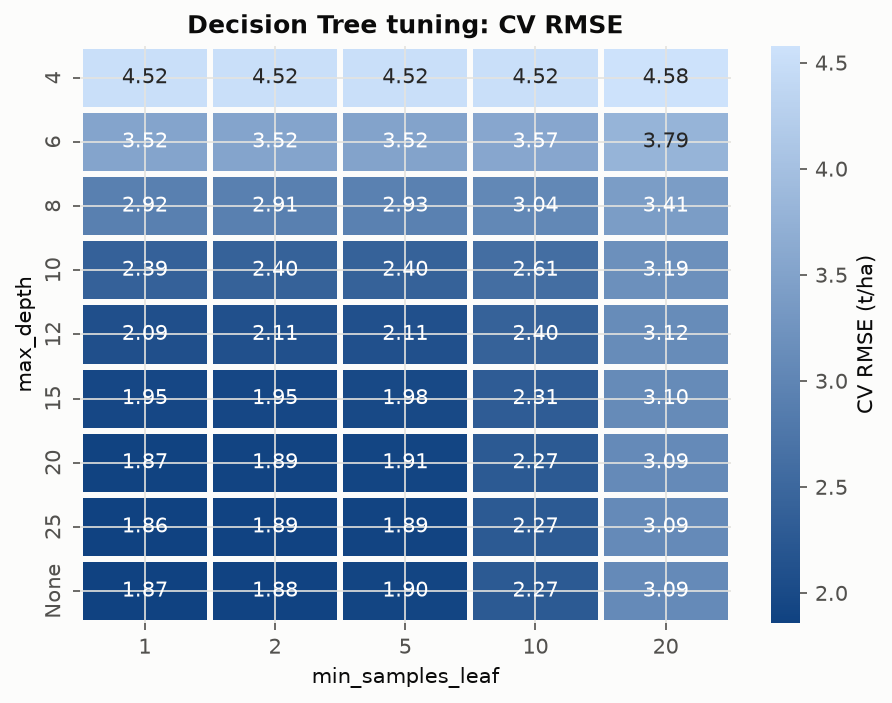

In [12]:
section("11. MACHINE LEARNING MODELS (tuned with 5-fold CV on training data)")
prep_tree = make_prep(SEL_NUM, SEL_CAT, scale=False)
t0 = time.time()
dt_gs = GridSearchCV(Pipeline([("prep", prep_tree), ("model", DecisionTreeRegressor(random_state=SEED))]),
                     {"model__max_depth": [4, 6, 8, 10, 12, 15, 20, 25, None],
                      "model__min_samples_leaf": [1, 2, 5, 10, 20]},
                     cv=CV, scoring="neg_root_mean_squared_error", n_jobs=N_JOBS).fit(X_train, y_train)
print(f"Decision Tree ({time.time() - t0:.0f}s): best = {dt_gs.best_params_}, CV RMSE = {-dt_gs.best_score_:.4f}")
t0 = time.time()
rf_gs = GridSearchCV(Pipeline([("prep", prep_tree),
                               ("model", RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=1))]),
                     {"model__max_features": ["sqrt", 0.33, 0.6, 1.0],
                      "model__min_samples_leaf": [1, 2, 4],
                      "model__max_depth": [None, 20]},
                     cv=CV, scoring="neg_root_mean_squared_error", n_jobs=N_JOBS).fit(X_train, y_train)
print(f"Random Forest ({time.time() - t0:.0f}s): best = {rf_gs.best_params_}, CV RMSE = {-rf_gs.best_score_:.4f}")
t0 = time.time()
gb_gs = GridSearchCV(Pipeline([("prep", prep_tree),
                               ("model", HistGradientBoostingRegressor(random_state=SEED))]),
                     {"model__learning_rate": [0.05, 0.1], "model__max_iter": [300, 800],
                      "model__max_leaf_nodes": [31, 63], "model__min_samples_leaf": [10, 20]},
                     cv=CV, scoring="neg_root_mean_squared_error", n_jobs=N_JOBS).fit(X_train, y_train)
print(f"Gradient Boosting ({time.time() - t0:.0f}s): best = {gb_gs.best_params_}, CV RMSE = {-gb_gs.best_score_:.4f}")

dt_res = pd.DataFrame(dt_gs.cv_results_)
dt_res["depth"] = dt_res["param_model__max_depth"].map(lambda v: "None" if v is None or pd.isna(v) else str(int(v)))
dt_res["leaf"] = dt_res["param_model__min_samples_leaf"].astype(int)
piv = dt_res.pivot_table(index="depth", columns="leaf", values="mean_test_score")
piv = piv.loc[sorted(piv.index, key=lambda s: 999 if s == "None" else int(s))]
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(-piv, annot=True, fmt=".2f", cmap=LinearSegmentedColormap.from_list("b", ["#104281", "#cde2fb"]),
            linewidths=2, linecolor=SURFACE, ax=ax, cbar_kws={"label": "CV RMSE (t/ha)"})
ax.set(title="Decision Tree tuning: CV RMSE", xlabel="min_samples_leaf", ylabel="max_depth")
savefig("17_dt_tuning_heatmap")

RESULTS["ml_tuning"] = {n: {"best_params": {k.replace("model__", ""): (v if not isinstance(v, (np.floating, np.integer)) else v.item())
                                            for k, v in gs.best_params_.items()},
                            "cv_rmse": float(-gs.best_score_)}
                        for n, gs in [("Decision Tree", dt_gs), ("Random Forest", rf_gs),
                                      ("Gradient Boosting", gb_gs), ("Ridge", ridge_gs), ("LASSO", lasso_gs)]}

## 12. Unified evaluation of every model


12. MODEL EVALUATION AND COMPARISON


Hold-out test set (20%) + 5-fold CV on the training set:

                                R2    MAE     MSE   RMSE  Train_R2  Train_RMSE  CV_R2_mean  CV_R2_std  CV_RMSE_mean  CV_RMSE_std  CV_MAE_mean  fit_seconds  Overfit_gap_R2
Model                                                                                                                                                                     
Simple Linear Regression    0.0374 5.7294 61.9214 7.8690    0.0335      7.7508      0.0327     0.0062        7.7506       0.1650       5.7004       0.1003         -0.0039
Multiple Linear Regression  0.6151 3.1805 24.7623 4.9762    0.6066      4.9451      0.6054     0.0110        4.9509       0.1693       3.2267       0.1977         -0.0085
MLR (Phase 2 features, OLS) 0.7351 2.8622 17.0404 4.1280    0.7293      4.1023      0.7219     0.0089        4.1559       0.1228       2.8755       0.8268         -0.0058
Ridge Regression            0.7349 2.8616 17.0531 4.1295    0.7292      4.1025      0.7


Temporal hold-out: train n=10775 (1990-2009), test n=2355 (2010-2013)
Leave-countries-out: 5-fold GroupKFold, no country appears in both train and validation

                             Temporal_R2  Temporal_RMSE  Temporal_MAE  UnseenCountry_R2  UnseenCountry_R2_std  UnseenCountry_RMSE
Model                                                                                                                            
Simple Linear Regression          0.0061         8.7135        6.2055            0.0268                0.0297              7.7390
Multiple Linear Regression        0.6063         5.4839        3.5428            0.5891                0.0560              5.0112
MLR (Phase 2 features, OLS)       0.7045         4.7513        3.1911            0.4983                0.0639              5.5239
Ridge Regression                  0.7043         4.7531        3.1936            0.5248                0.0606              5.3769
LASSO Regression                  0.7045         4.7514     

  [figure saved] outputs/figures/18_model_comparison_bars.png


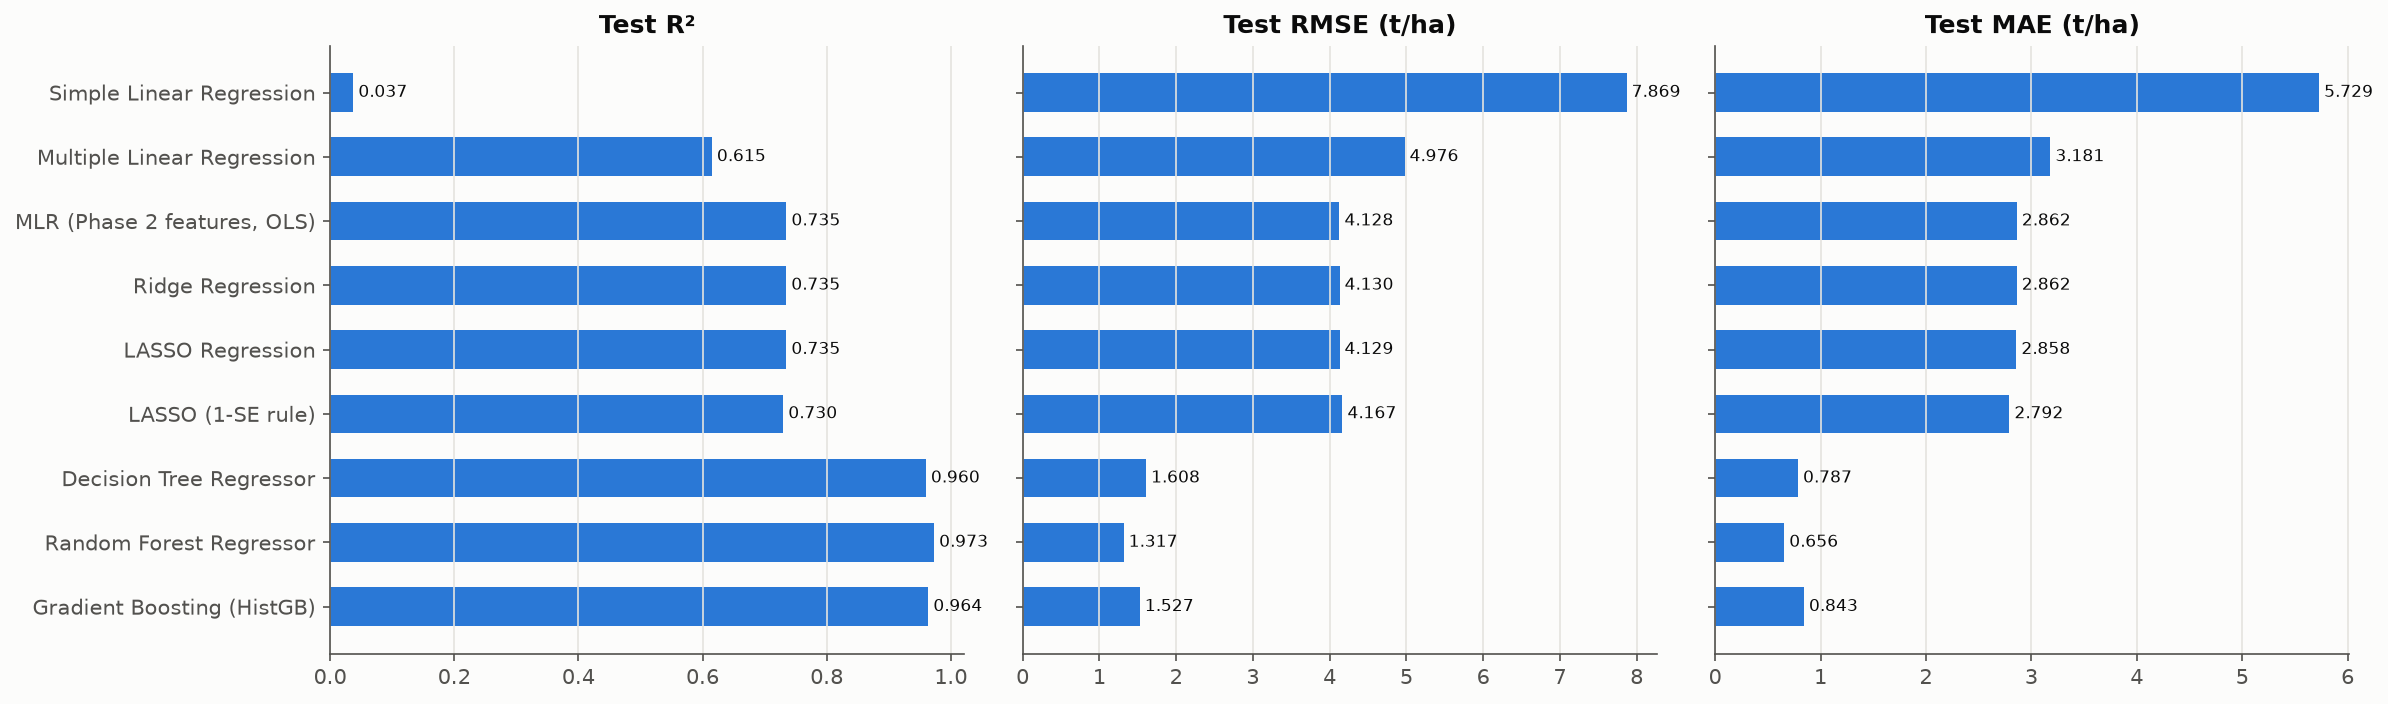

  [figure saved] outputs/figures/19_actual_vs_predicted.png


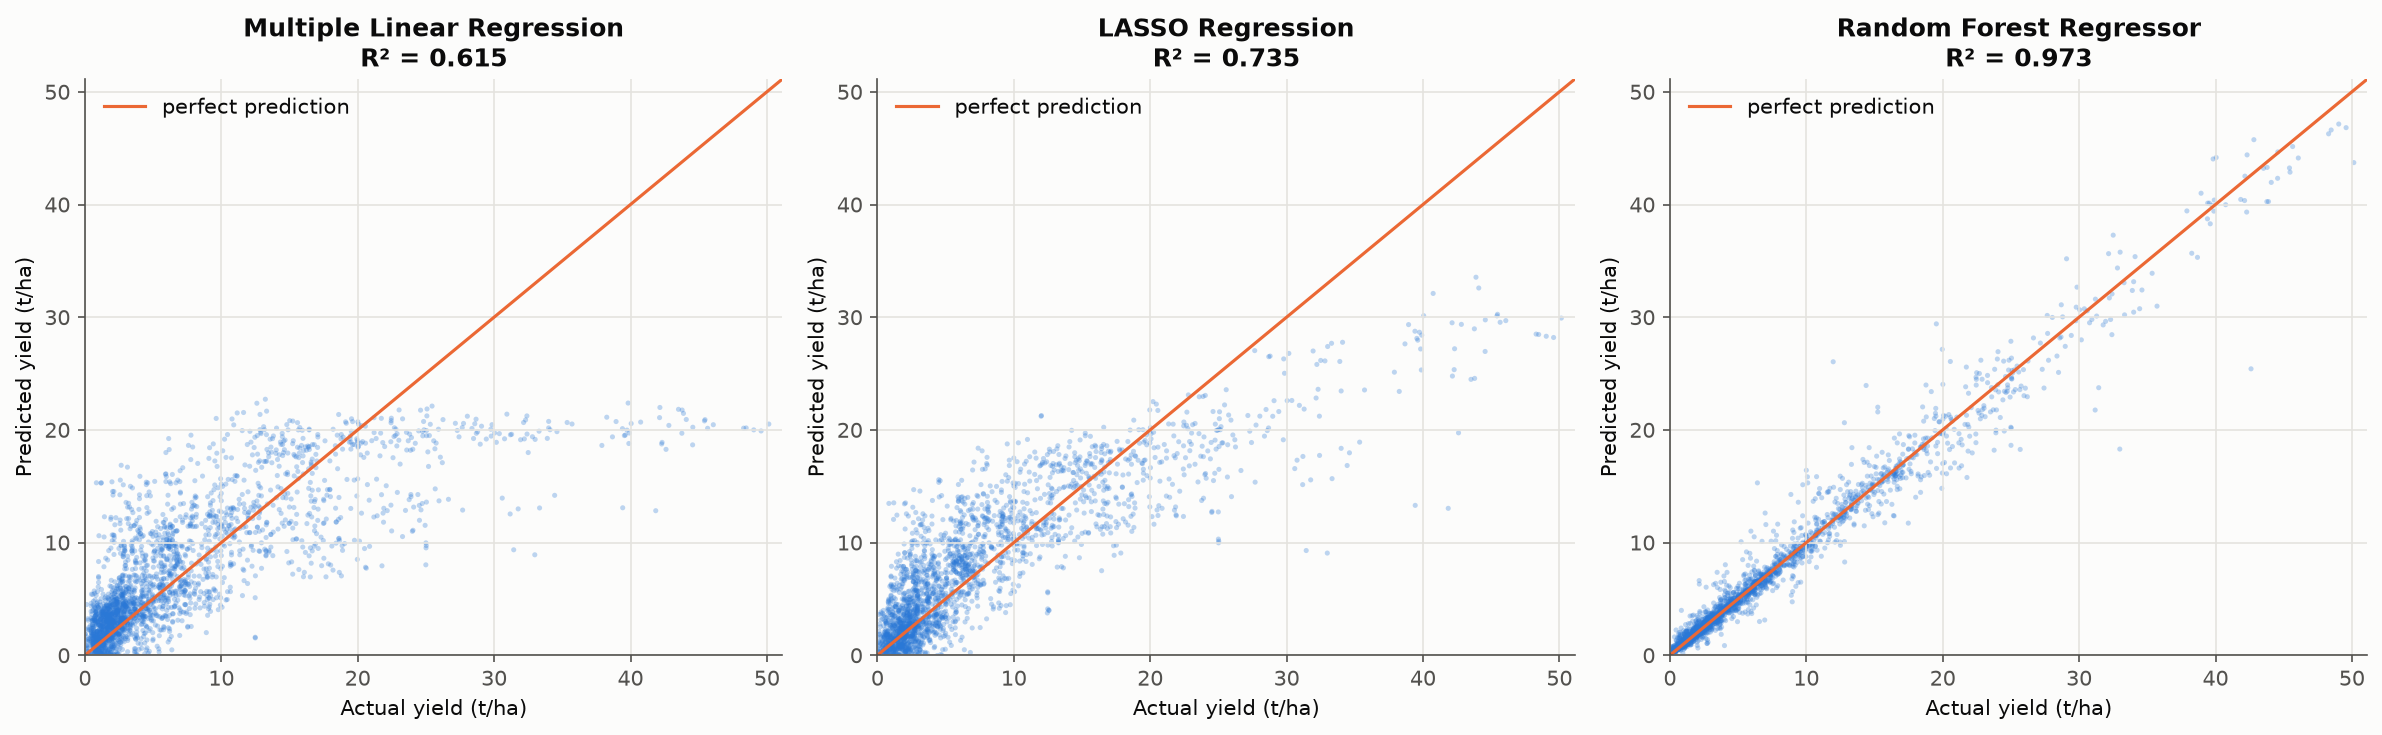

  [figure saved] outputs/figures/20_best_model_residuals.png


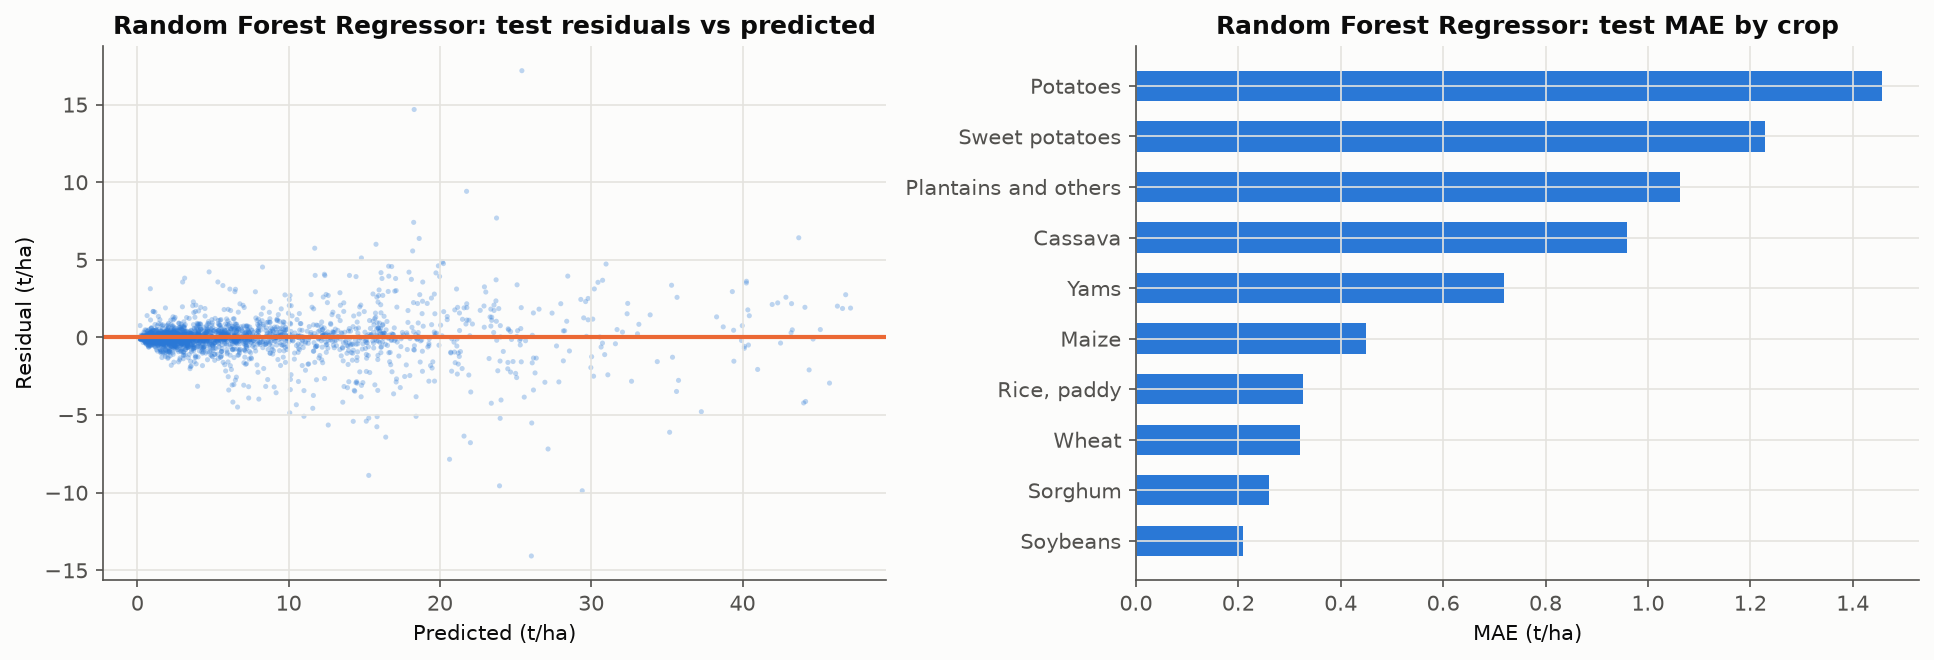

  [figure saved] outputs/figures/21_generalisation_r2.png


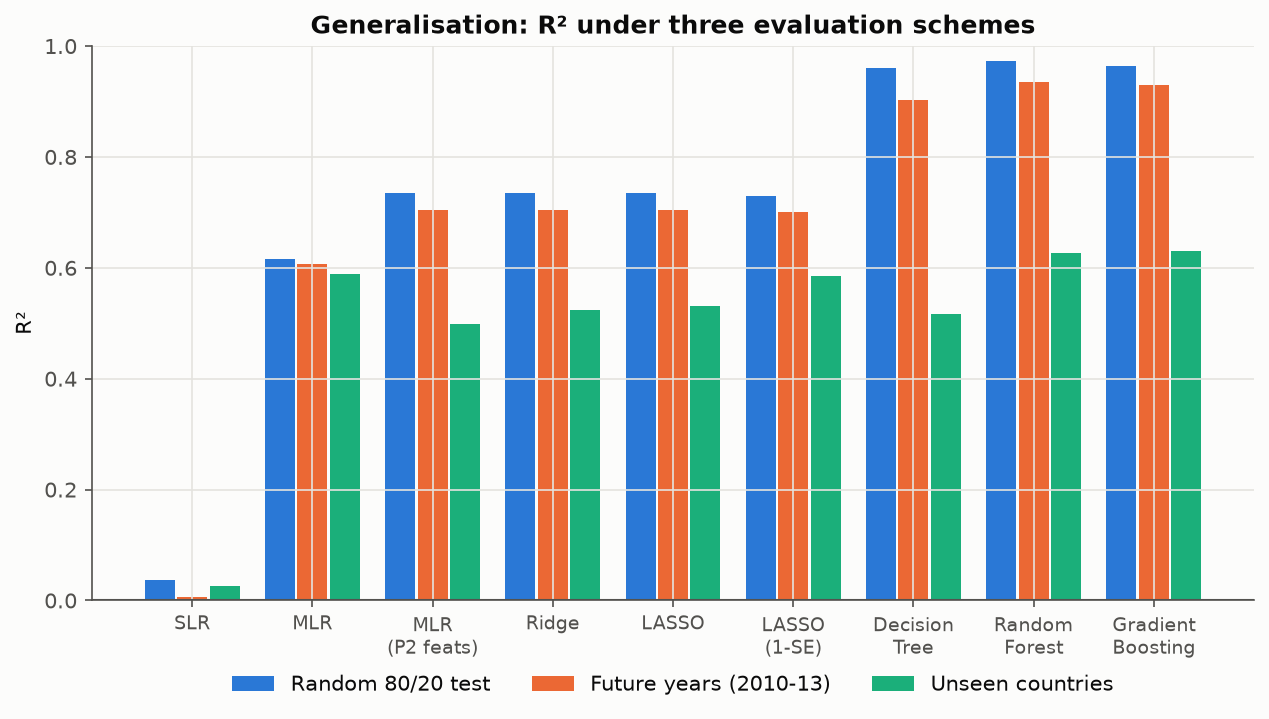


Feature-selection ablation (5-fold CV RMSE):
         model       features  cv_rmse
        LASSO       selected   4.1556
        LASSO all candidates   4.1556
Random Forest       selected   1.4706
Random Forest all candidates   1.4706


In [13]:
section("12. MODEL EVALUATION AND COMPARISON")
full_lin = Pipeline([("prep", ColumnTransformer([
    ("num", StandardScaler(), SEL_NUM),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), SEL_CAT)])),
    ("lr", LinearRegression())])
MODELS = {
    "Simple Linear Regression": slr_pipe,
    "Multiple Linear Regression": mlr_pipe,
    "MLR (Phase 2 features, OLS)": full_lin,
    "Ridge Regression": ridge_gs.best_estimator_,
    "LASSO Regression": lasso_gs.best_estimator_,
    "LASSO (1-SE rule)": lasso_1se,
    "Decision Tree Regressor": dt_gs.best_estimator_,
    "Random Forest Regressor": rf_gs.best_estimator_,
    "Gradient Boosting (HistGB)": gb_gs.best_estimator_,
}
SHORT = {"Simple Linear Regression": "SLR", "Multiple Linear Regression": "MLR",
         "MLR (Phase 2 features, OLS)": "MLR\n(P2 feats)", "Ridge Regression": "Ridge",
         "LASSO Regression": "LASSO", "LASSO (1-SE rule)": "LASSO\n(1-SE)",
         "Decision Tree Regressor": "Decision\nTree", "Random Forest Regressor": "Random\nForest",
         "Gradient Boosting (HistGB)": "Gradient\nBoosting"}
rows, fitted_models, test_preds = [], {}, {}
for name, est in MODELS.items():
    t0 = time.time()
    cvr = cross_validate(clone(est), X_train, y_train, cv=CV, n_jobs=N_JOBS,
                         scoring={"r2": "r2", "rmse": "neg_root_mean_squared_error",
                                  "mae": "neg_mean_absolute_error"})
    m = clone(est).fit(X_train, y_train)
    p_test, p_train = m.predict(X_test), m.predict(X_train)
    fitted_models[name], test_preds[name] = m, p_test
    te, tr = metrics(y_test, p_test), metrics(y_train, p_train)
    rows.append({"Model": name, "R2": te["R2"], "MAE": te["MAE"], "MSE": te["MSE"], "RMSE": te["RMSE"],
                 "Train_R2": tr["R2"], "Train_RMSE": tr["RMSE"],
                 "CV_R2_mean": cvr["test_r2"].mean(), "CV_R2_std": cvr["test_r2"].std(),
                 "CV_RMSE_mean": -cvr["test_rmse"].mean(), "CV_RMSE_std": cvr["test_rmse"].std(),
                 "CV_MAE_mean": -cvr["test_mae"].mean(), "fit_seconds": time.time() - t0})
comparison = pd.DataFrame(rows).set_index("Model")
comparison["Overfit_gap_R2"] = comparison["Train_R2"] - comparison["R2"]
print("Hold-out test set (20%) + 5-fold CV on the training set:\n")
print(comparison.round(4).to_string())
comparison.to_csv(TAB / "model_comparison.csv")

# Robustness 1: temporal hold-out (train 1990-2009, test 2010-2013) - forecasting future years
tmp_tr, tmp_te = df[df.year <= 2009], df[df.year >= 2010]
# Robustness 2: leave-countries-out (GroupKFold by country) - predicting unseen regions
gkf = GroupKFold(n_splits=5)
rob_rows = []
for name, est in MODELS.items():
    mt = clone(est).fit(tmp_tr[ALL_FEATURES], tmp_tr[TARGET])
    tm = metrics(tmp_te[TARGET], mt.predict(tmp_te[ALL_FEATURES]))
    g = cross_validate(clone(est), df[ALL_FEATURES], df[TARGET], groups=df["country"], cv=gkf,
                       scoring={"r2": "r2", "rmse": "neg_root_mean_squared_error"}, n_jobs=N_JOBS)
    rob_rows.append({"Model": name, "Temporal_R2": tm["R2"], "Temporal_RMSE": tm["RMSE"],
                     "Temporal_MAE": tm["MAE"], "UnseenCountry_R2": g["test_r2"].mean(),
                     "UnseenCountry_R2_std": g["test_r2"].std(),
                     "UnseenCountry_RMSE": -g["test_rmse"].mean()})
robust = pd.DataFrame(rob_rows).set_index("Model")
print(f"\nTemporal hold-out: train n={len(tmp_tr)} (1990-2009), test n={len(tmp_te)} (2010-2013)")
print("Leave-countries-out: 5-fold GroupKFold, no country appears in both train and validation\n")
print(robust.round(4).to_string())
robust.to_csv(TAB / "robustness_temporal_and_unseen_country.csv")

RESULTS["comparison"] = comparison.round(5).reset_index().to_dict(orient="records")
RESULTS["robustness"] = robust.round(5).reset_index().to_dict(orient="records")
RESULTS["temporal_sizes"] = {"train": int(len(tmp_tr)), "test": int(len(tmp_te))}

# Comparison plots
plot_models = list(MODELS)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, (col, lab) in zip(axes, [("R2", "Test R²"), ("RMSE", "Test RMSE (t/ha)"), ("MAE", "Test MAE (t/ha)")]):
    vals = comparison.loc[plot_models, col]
    ax.barh(plot_models, vals, color=BLUE, height=0.6)
    for yv_, v in enumerate(vals):
        ax.text(v, yv_, f" {v:.3f}", va="center", fontsize=8, color=INK)
    ax.set_title(lab)
    ax.invert_yaxis() if ax is axes[0] else None
    ax.grid(axis="y", visible=False)
plt.tight_layout()
savefig("18_model_comparison_bars")

best_name = comparison["RMSE"].idxmin()
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, name in zip(axes, ["Multiple Linear Regression", "LASSO Regression", best_name]):
    p = test_preds[name]
    ax.scatter(y_test, p, s=6, alpha=0.3, color=BLUE, edgecolors="none")
    lim = [0, max(y_test.max(), p.max()) * 1.02]
    ax.plot(lim, lim, color=ORANGE, linewidth=1.5, label="perfect prediction")
    ax.set(xlim=lim, ylim=lim, title=f"{name}\nR² = {r2_score(y_test, p):.3f}",
           xlabel="Actual yield (t/ha)", ylabel="Predicted yield (t/ha)")
    ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
savefig("19_actual_vs_predicted")

res_best = y_test - test_preds[best_name]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(test_preds[best_name], res_best, s=6, alpha=0.3, color=BLUE, edgecolors="none")
axes[0].axhline(0, color=ORANGE)
axes[0].set(title=f"{best_name}: test residuals vs predicted", xlabel="Predicted (t/ha)", ylabel="Residual (t/ha)")
err_crop = pd.DataFrame({"crop": test_df["crop"], "abs_err": np.abs(res_best)}).groupby("crop")["abs_err"].mean().sort_values()
axes[1].barh(err_crop.index, err_crop.values, color=BLUE, height=0.6)
axes[1].set(title=f"{best_name}: test MAE by crop", xlabel="MAE (t/ha)")
plt.tight_layout()
savefig("20_best_model_residuals")
RESULTS["best_model_mae_by_crop"] = err_crop.round(4).to_dict()

fig, ax = plt.subplots(figsize=(10, 4.8))
xpos = np.arange(len(plot_models))
w = 0.27
for k, (col, lab, colr) in enumerate([("R2", "Random 80/20 test", BLUE),
                                      ("Temporal_R2", "Future years (2010-13)", ORANGE),
                                      ("UnseenCountry_R2", "Unseen countries", "#1baf7a")]):
    vals = comparison.loc[plot_models, col] if col == "R2" else robust.loc[plot_models, col]
    ax.bar(xpos + (k - 1) * w, vals, width=w - 0.02, color=colr, label=lab)
ax.set_xticks(xpos, [SHORT[m] for m in plot_models], fontsize=9)
ax.axhline(0, color=INK2, linewidth=1)
ax.set(title="Generalisation: R² under three evaluation schemes", ylabel="R²", ylim=(0, 1.0))
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
savefig("21_generalisation_r2")

# Ablation: does feature selection matter?  (all 6 candidate features vs selected)
abl = []
for name, base in [("LASSO", lasso_gs.best_estimator_), ("Random Forest", rf_gs.best_estimator_)]:
    for label, (nu, ca) in [("selected", (SEL_NUM, SEL_CAT)), ("all candidates", (NUM, CAT))]:
        est = clone(base)
        est.set_params(prep=make_prep(nu, ca, scale=(name == "LASSO")))
        s = cross_validate(est, X_train, y_train, cv=CV, scoring="neg_root_mean_squared_error", n_jobs=N_JOBS)
        abl.append({"model": name, "features": label, "cv_rmse": -s["test_score"].mean()})
abl = pd.DataFrame(abl)
print("\nFeature-selection ablation (5-fold CV RMSE):\n", abl.round(4).to_string(index=False))
RESULTS["ablation"] = abl.round(5).to_dict(orient="records")

## 13. Final model and prediction examples

In [14]:
section("13. FINAL MODEL AND PREDICTION EXAMPLES")
print(f"Lowest test RMSE: {best_name}")
final = fitted_models[best_name]
ex = test_df.sample(8, random_state=SEED)
ex_out = ex[["country", "crop", "year", "avg_rainfall_mm", "pesticides_tonnes", "avg_temp_c", TARGET]].copy()
ex_out["pred_" + best_name.split()[0]] = final.predict(ex[ALL_FEATURES])
ex_out["pred_MLR"] = fitted_models["Multiple Linear Regression"].predict(ex[ALL_FEATURES])
print("Predictions for 8 random test-set rows (unseen during training):\n", ex_out.round(3).to_string(index=False))
ex_out.to_csv(TAB / "prediction_examples.csv", index=False)


def predict_yield(country, crop, year, rainfall_mm, pesticides_tonnes, temp_c, model=final):
    row = pd.DataFrame([{"country": country, "crop": crop, "year": year, "avg_rainfall_mm": rainfall_mm,
                         "log_pesticides": np.log1p(pesticides_tonnes), "avg_temp_c": temp_c}])
    return float(model.predict(row[ALL_FEATURES])[0])


# Scenario: India, wheat and rice, 2013 inputs; temperature shifted +1 / +2 °C.
# This shows model SENSITIVITY only; it is not a causal climate-impact estimate.
scen = []
for crop in ["Wheat", "Rice, paddy"]:
    base = df[(df.country == "India") & (df.crop == crop) & (df.year == 2013)].iloc[0]
    for dT in [0, 1, 2]:
        scen.append({"country": "India", "crop": crop, "year": 2013, "temp_c": round(base.avg_temp_c + dT, 2),
                     "delta_T": dT, "actual_2013": base[TARGET] if dT == 0 else np.nan,
                     "predicted": predict_yield("India", crop, 2013, base.avg_rainfall_mm,
                                                base.pesticides_tonnes, base.avg_temp_c + dT)})
scen = pd.DataFrame(scen)
print("\nScenario predictions (model sensitivity, not causal effects):\n", scen.round(3).to_string(index=False))
RESULTS["examples"] = ex_out.round(4).to_dict(orient="records")
RESULTS["scenario"] = scen.round(4).to_dict(orient="records")
RESULTS["best_model"] = best_name

with open(OUT / "results.json", "w", encoding="utf-8") as f:
    json.dump(RESULTS, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("\nAll results written to outputs/results.json")


13. FINAL MODEL AND PREDICTION EXAMPLES
Lowest test RMSE: Random Forest Regressor
Predictions for 8 random test-set rows (unseen during training):
                  country                 crop  year  avg_rainfall_mm  pesticides_tonnes  avg_temp_c  yield_t_ha  pred_Random  pred_MLR
                  Greece          Rice, paddy  2011         652.0000         8,189.8000     17.6700      8.1090       7.4310    5.9390
                  Zambia          Rice, paddy  2001       1,020.0000         1,670.0000     20.9000      1.2560       1.1550    3.6160
                  Malawi Plantains and others  1999       1,181.0000           123.6400     20.2600      4.8810       5.9340   10.7620
Central African Republic                 Yams  1997       1,342.0000            22.8700     25.6900      6.6670       6.6910    7.8930
                Bulgaria          Rice, paddy  2000         608.0000         2,876.0000      9.9000      4.7000       4.3020    5.6150
          United Kingdom             Pota


Scenario predictions (model sensitivity, not causal effects):
 country        crop  year  temp_c  delta_T  actual_2013  predicted
  India       Wheat  2013 26.7900        0       3.1540     3.0320
  India       Wheat  2013 27.7900        1          NaN     2.6670
  India       Wheat  2013 28.7900        2          NaN     2.6810
  India Rice, paddy  2013 26.7900        0       3.6070     3.5480
  India Rice, paddy  2013 27.7900        1          NaN     3.4510
  India Rice, paddy  2013 28.7900        2          NaN     3.4350

All results written to outputs/results.json
